<a href="https://colab.research.google.com/github/eng-mohamedfathy/Land-Type-Classification/blob/main/Land_Type_Classification_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Land Type Classification Using Deep Learning and Satellite Imagery

This notebook builds a 10-class EuroSAT image classifier with a pretrained ResNet50. Run the cells in order in Google Colab. The training cell is intentionally separate so you can start training when you are ready.

**Workflow:** data audit and preparation → transfer learning → validation → final test evaluation → saved model and image inference.


## 1. Project Overview

EuroSAT contains 27,000 RGB satellite images across 10 land-cover classes. The target split is 70% training, 15% validation, and 15% testing. ResNet50 expects 224 × 224 inputs, so the original 64 × 64 images will be resized.

In [1]:
PROJECT_NAME = "Land Type Classification Using Deep Learning and Satellite Imagery"
DATASET_NAME = "EuroSAT"
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print(PROJECT_NAME)
print(f"Dataset: {DATASET_NAME} | Classes: {NUM_CLASSES} | Input: {IMAGE_SIZE}x{IMAGE_SIZE} RGB")
print(f"Split: 70% train / 15% validation / 15% test | Batch size: {BATCH_SIZE}")

Land Type Classification Using Deep Learning and Satellite Imagery
Dataset: EuroSAT | Classes: 10 | Input: 224x224 RGB
Split: 70% train / 15% validation / 15% test | Batch size: 32


## 2. Environment Setup

Import the project dependencies, set reproducibility controls, and select the available GPU when Colab provides one. Colab already includes the required packages in its standard PyTorch runtime.

In [2]:
import copy
import random
import sys
import time
from pathlib import Path
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import EuroSAT

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/eurosat_data") if Path("/content").exists() else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; training will use CPU and take longer.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


## 3. Dataset Collection

Load EuroSAT through torchvision. The download is performed only if the dataset is not already present in the selected data directory.

In [3]:
dataset = EuroSAT(root=str(DATA_DIR), download=True)
class_names = dataset.classes
targets = np.asarray(dataset.targets, dtype=np.int64)

print("Dataset downloaded and loaded.")
print("Total images:", len(dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

100%|██████████| 94.3M/94.3M [00:00<00:00, 119MB/s]


Dataset downloaded and loaded.
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 4. Exploratory Data Analysis (EDA)

Check the number of images in each class and visualize the distribution. EuroSAT is close to balanced, with modest differences in a few class counts.

                  Class  Number of Images
0            AnnualCrop              3000
1                Forest              3000
2  HerbaceousVegetation              3000
3               Highway              2500
4            Industrial              2500
5               Pasture              2000
6         PermanentCrop              2500
7           Residential              3000
8                 River              2500
9               SeaLake              3000


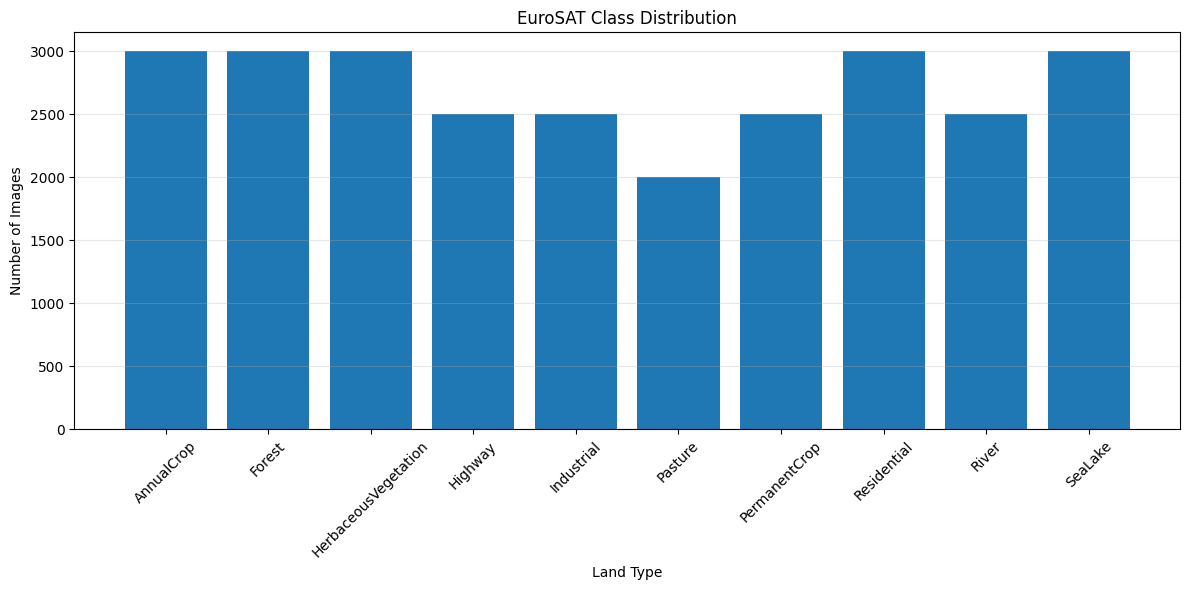

In [4]:
class_counts = pd.Series(dataset.targets).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": dataset.classes,
    "Number of Images": class_counts.values
})

print(class_distribution)

plt.figure(figsize=(12, 6))
plt.bar(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)
plt.title("EuroSAT Class Distribution")
plt.xlabel("Land Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Image Understanding

Display one representative image from each class. The examples remain in their original 64 × 64 RGB form at this stage.

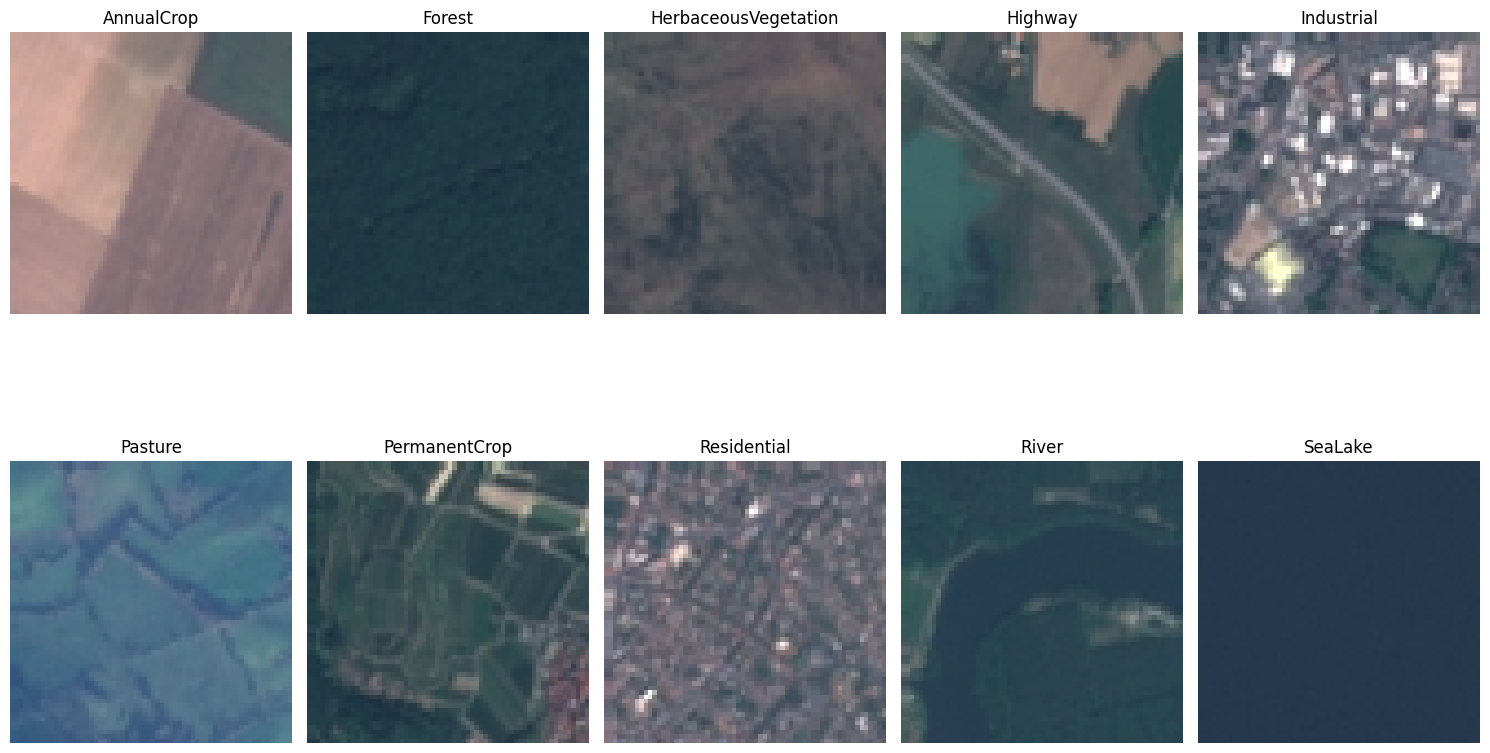

In [5]:
class_images = defaultdict(list)
for index, label in enumerate(targets):
    class_images[int(label)].append(index)

plt.figure(figsize=(15, 10))
for class_id, class_name in enumerate(class_names):
    image_index = random.choice(class_images[class_id])
    image, _ = dataset[image_index]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Inspect a raw sample before defining model transforms. EuroSAT images are RGB PIL images with 8-bit pixel values; resizing and normalization are applied in the transformation stage.

In [6]:
sample_image, sample_label = dataset[0]
image_array = np.asarray(sample_image)

print("Image class:", class_names[sample_label])
print("Image mode:", sample_image.mode)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Pixel range:", int(image_array.min()), "to", int(image_array.max()))

assert sample_image.mode == "RGB", "Expected an RGB image."
assert image_array.shape == (64, 64, 3), "Expected a 64x64 RGB EuroSAT image."

Image class: AnnualCrop
Image mode: RGB
Image shape: (64, 64, 3)
Image data type: uint8
Pixel range: 82 to 204


## 7. Dataset Splitting

Create reproducible stratified splits so each subset keeps approximately the same class distribution. The test set is held out until the final evaluation.

In [7]:
all_indices = np.arange(len(targets))

test_count = int(round(0.15 * len(all_indices)))
val_count = int(round(0.15 * len(all_indices)))

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=test_count,
    random_state=SEED,
    stratify=targets,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_count,
    random_state=SEED,
    stratify=targets[train_val_indices],
)

split_summary = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(targets[train_indices], minlength=NUM_CLASSES),
    "Validation": np.bincount(targets[val_indices], minlength=NUM_CLASSES),
    "Test": np.bincount(targets[test_indices], minlength=NUM_CLASSES),
})

print(f"Training images:   {len(train_indices):,}")
print(f"Validation images: {len(val_indices):,}")
print(f"Testing images:    {len(test_indices):,}")
display(split_summary)

assert (len(train_indices), len(val_indices), len(test_indices)) == (18_900, 4_050, 4_050)

Training images:   18,900
Validation images: 4,050
Testing images:    4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 8. Image Transformations

Resize each image to 224 × 224 and apply ImageNet normalization expected by pretrained ResNet50 weights. Random flips and rotation are used only for training; validation and test transforms are deterministic.

In [8]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training and evaluation transforms are ready.")

Training and evaluation transforms are ready.


## 9. Dataset Preparation

Create separate dataset views so random augmentation is applied to training examples only. Each view uses the same underlying EuroSAT file ordering as the stratified indices.

In [9]:
train_data = EuroSAT(root=str(DATA_DIR), download=False, transform=train_transform)
eval_data = EuroSAT(root=str(DATA_DIR), download=False, transform=eval_transform)

train_set = Subset(train_data, train_indices.tolist())
val_set = Subset(eval_data, val_indices.tolist())
test_set = Subset(eval_data, test_indices.tolist())

assert train_data.classes == class_names
assert eval_data.classes == class_names
print("Prepared dataset sizes:", len(train_set), len(val_set), len(test_set))

Prepared dataset sizes: 18900 4050 4050


## 10. DataLoader Creation

Load batches of 32 images. Pinned memory is enabled on GPU systems, while a small worker count keeps Colab memory use manageable.

In [10]:
NUM_WORKERS = 2 if device.type == "cuda" else 0
loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
}

train_loader = DataLoader(train_set, shuffle=True, **loader_settings)
val_loader = DataLoader(val_set, shuffle=False, **loader_settings)
test_loader = DataLoader(test_set, shuffle=False, **loader_settings)

images_batch, labels_batch = next(iter(train_loader))
print("Image batch shape:", tuple(images_batch.shape))
print("Label batch shape:", tuple(labels_batch.shape))
print("Batch size:", BATCH_SIZE)
del images_batch, labels_batch

Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)
Batch size: 32


## 11. Model Building (ResNet50)

Initialize ResNet50 with ImageNet pretrained weights and replace its final fully connected layer with a 10-class classifier. The first run may download the pretrained weights.

In [11]:
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

print("Architecture: ResNet50")
print("Output classes:", model.fc.out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 351MB/s]


Architecture: ResNet50
Output classes: 10
Device: cuda


## 12. Transfer Learning Configuration

Freeze the earlier feature extractor and fine-tune the final ResNet block (`layer4`) together with the new classifier. This reduces trainable parameters and GPU memory use while adapting high-level features to EuroSAT.

In [12]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")

Trainable parameters: 14,985,226 / 23,528,522


## 13. Loss Function and Optimizer

Use multiclass cross-entropy and Adam. Only parameters enabled for fine-tuning are passed to the optimizer.

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (parameter for parameter in model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 14. Model Training

Define reusable epoch functions. Training loss and accuracy are averaged over examples, and the frozen backbone's BatchNorm layers keep their pretrained running statistics.

In [14]:
def run_epoch(loader, training=False):
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_count

    return total_loss / total, correct / total

print("Training and validation epoch functions are ready.")

Training and validation epoch functions are ready.


## 15. Validation and Performance Monitoring

This is the training cell. It runs one training and one validation pass per epoch, tracks loss and accuracy, and retains the weights with the lowest validation loss. Execute it manually when ready; no training is started by the setup cells.

Epoch 01/15 | train loss 0.3261, accuracy 0.9110 | val loss 0.0953, accuracy 0.9706 | 11.1s
Epoch 02/15 | train loss 0.0979, accuracy 0.9679 | val loss 0.0752, accuracy 0.9758 | 9.9s
Epoch 03/15 | train loss 0.0677, accuracy 0.9764 | val loss 0.0781, accuracy 0.9728 | 10.0s
Epoch 04/15 | train loss 0.0510, accuracy 0.9827 | val loss 0.0647, accuracy 0.9793 | 10.2s
Epoch 05/15 | train loss 0.0446, accuracy 0.9854 | val loss 0.0571, accuracy 0.9822 | 10.5s
Epoch 06/15 | train loss 0.0321, accuracy 0.9898 | val loss 0.0559, accuracy 0.9849 | 9.9s
Epoch 07/15 | train loss 0.0284, accuracy 0.9905 | val loss 0.0561, accuracy 0.9847 | 10.5s
Epoch 08/15 | train loss 0.0271, accuracy 0.9907 | val loss 0.0692, accuracy 0.9810 | 10.5s
Epoch 09/15 | train loss 0.0216, accuracy 0.9932 | val loss 0.0675, accuracy 0.9817 | 10.3s
Epoch 10/15 | train loss 0.0163, accuracy 0.9950 | val loss 0.0651, accuracy 0.9825 | 10.7s
Early stopping: validation loss did not improve for 4 epochs.
Best epoch: 6 | best

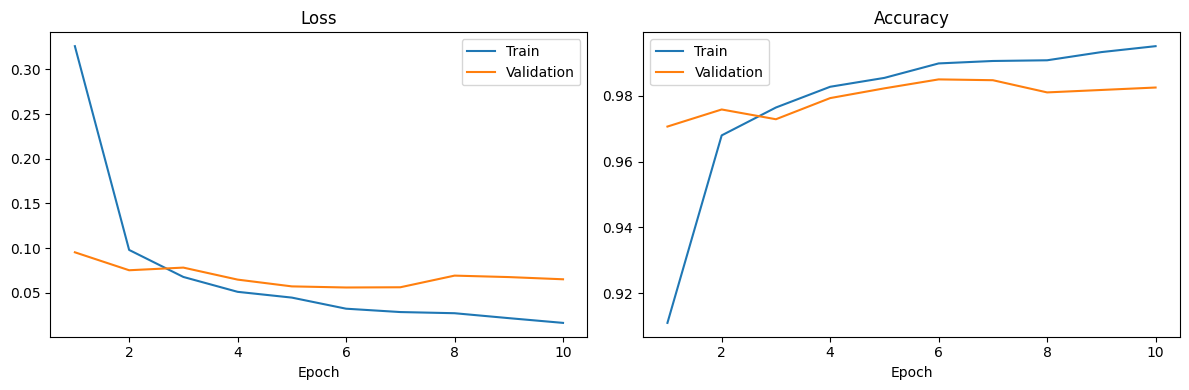

In [15]:
NUM_EPOCHS = 15
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{elapsed:.1f}s"
    )
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

if best_model_state is None:
    raise RuntimeError("Training did not produce a best model checkpoint.")
model.load_state_dict(best_model_state)
print(f"Best epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}")

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 16. Model Evaluation

Restore the best validation checkpoint and evaluate the held-out test set once. Do not use these test results to tune the model.

In [16]:
if best_model_state is None:
    raise RuntimeError("Run the training cell before evaluating the model.")
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test accuracy: {test_accuracy:.4f}")

Test accuracy: 0.9820


## 17. Confusion Matrix

Show how often each true class is predicted as each class. Rows are true labels and columns are predicted labels.

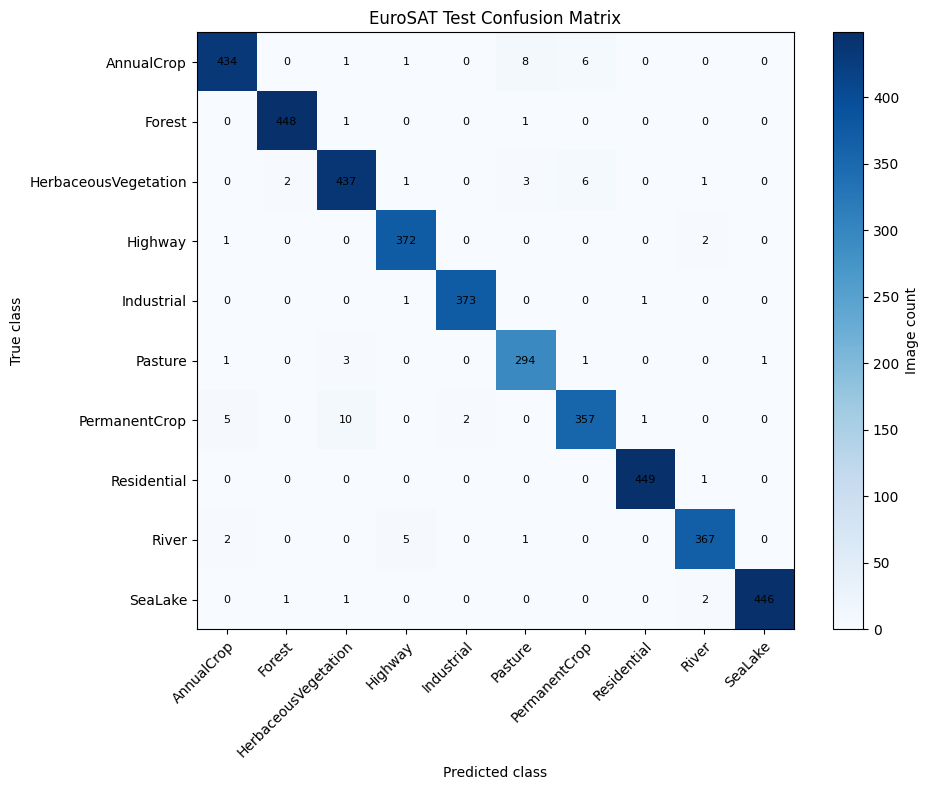

In [17]:
confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 18. Classification Report

Report per-class precision, recall, and F1-score, together with macro and weighted averages.

In [18]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9797    0.9644    0.9720       450
              Forest     0.9933    0.9956    0.9945       450
HerbaceousVegetation     0.9647    0.9711    0.9679       450
             Highway     0.9789    0.9920    0.9854       375
          Industrial     0.9947    0.9947    0.9947       375
             Pasture     0.9577    0.9800    0.9687       300
       PermanentCrop     0.9649    0.9520    0.9584       375
         Residential     0.9956    0.9978    0.9967       450
               River     0.9839    0.9787    0.9813       375
             SeaLake     0.9978    0.9911    0.9944       450

            accuracy                         0.9820      4050
           macro avg     0.9811    0.9817    0.9814      4050
        weighted avg     0.9820    0.9820    0.9820      4050



## 19. Model Saving

Save the best model weights and the class/preprocessing metadata needed to reproduce predictions. In Colab, download this file or save it to mounted Google Drive if you need it after the runtime ends.

In [19]:
MODEL_PATH = Path("best_resnet50_eurosat.pth")
checkpoint = {
    "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
}
torch.save(checkpoint, MODEL_PATH)
print("Saved model to:", MODEL_PATH.resolve())

Saved model to: /content/best_resnet50_eurosat.pth


## 20. Model Loading and Inference

Rebuild the model architecture without downloading weights, load the saved checkpoint, and define a prediction function that applies the same evaluation preprocessing.

In [20]:
loaded_checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
loaded_class_names = loaded_checkpoint["class_names"]
loaded_model = models.resnet50(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, len(loaded_class_names))
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device).eval()

inference_transform = transforms.Compose([
    transforms.Resize((loaded_checkpoint["image_size"], loaded_checkpoint["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=loaded_checkpoint["imagenet_mean"],
        std=loaded_checkpoint["imagenet_std"],
    ),
])

def classify_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(loaded_model(image_tensor), dim=1)[0]
    predicted_index = int(probabilities.argmax().item())
    return loaded_class_names[predicted_index], float(probabilities[predicted_index].item())

print("Loaded model ready for single-image inference.")

Loaded model ready for single-image inference.


## 21. Testing with New Satellite Images

Upload one or more RGB satellite images in Google Colab. The model returns its most likely land-cover class and the associated softmax score.

In [21]:
from google.colab import files

uploaded_files = files.upload()
for filename in uploaded_files:
    predicted_class, confidence = classify_image(filename)
    print(f"{filename}: {predicted_class} (score: {confidence:.3f})")

Saving images-1.jpg to images-1.jpg
images-1.jpg: HerbaceousVegetation (score: 0.966)


## 22. Final Conclusion

After running the notebook in order, you will have a reproducible EuroSAT training pipeline, a validation-selected ResNet50 checkpoint, final held-out test metrics, and a function for classifying new satellite images. Record the observed metrics in your project report after the final evaluation.

In [22]:
if "test_accuracy" in globals():
    print(f"Final held-out test accuracy: {test_accuracy:.4f}")
    print("See the classification report and confusion matrix above for detailed results.")
else:
    print("Run the training and evaluation cells to generate final test results.")
print("Inference function: classify_image(image_path)")

Final held-out test accuracy: 0.9820
See the classification report and confusion matrix above for detailed results.
Inference function: classify_image(image_path)


# Phase 2 — Model Comparison and Project Extensions

The completed ResNet50 work above is preserved as the project baseline. The sections below add an EfficientNet-B0 experiment, deeper error analysis, Grad-CAM, a clearly separate multispectral roadmap, optimization notes, and an optional Gradio interface. Run these cells one at a time after the relevant earlier cells. **No new model training starts until the dedicated training cell is run.**

The saved ResNet50 outputs report 98.20% test accuracy on 4,050 held-out images. EfficientNet-B0 metrics are intentionally left unreported until its training and test-evaluation cells have actually run.


## 23. Baseline Audit and Comparison Setup

Summarize the real ResNet50 test predictions already produced above. Its per-epoch times were printed to one decimal place; their sum is an estimate, not an exact timer measurement. The checkpoint size is read from the saved file when it is available.

In [23]:
baseline_report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

# Recorded epoch durations from the existing ResNet50 run (rounded to 0.1 s).
baseline_epoch_seconds = [12.3, 8.8, 10.5, 9.4, 10.4, 10.1, 10.2, 10.6, 10.6, 10.4]
baseline_training_seconds_approx = sum(baseline_epoch_seconds)
baseline_checkpoint_path = Path(MODEL_PATH)
baseline_checkpoint_mb = (
    baseline_checkpoint_path.stat().st_size / (1024 ** 2)
    if baseline_checkpoint_path.exists()
    else np.nan
)

baseline_audit = pd.DataFrame([{
    "Model": "ResNet50",
    "Test images": len(all_labels),
    "Test accuracy": accuracy_score(all_labels, all_predictions),
    "Macro precision": baseline_report_dict["macro avg"]["precision"],
    "Macro recall": baseline_report_dict["macro avg"]["recall"],
    "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
    "Training time (s, approx.)": baseline_training_seconds_approx,
    "Checkpoint size (MiB)": baseline_checkpoint_mb,
}])
display(baseline_audit.round(4))
print("Training-time estimate uses the rounded epoch durations saved in the baseline output.")

,Model,Test images,Test accuracy,Macro precision,Macro recall,Macro F1,"Training time (s, approx.)",Checkpoint size (MiB)
0,ResNet50,4050,0.982,0.9811,0.9817,0.9814,103.3,90.0526


Training-time estimate uses the rounded epoch durations saved in the baseline output.


## 24. EfficientNet-B0 Model Building

Load torchvision's ImageNet-pretrained EfficientNet-B0 and replace its last classifier layer with a 10-class head. The first execution may download pretrained weights. The existing 224 × 224 transforms and ImageNet normalization are compatible. [Torchvision model documentation](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html).

In [24]:
torch.manual_seed(SEED + 1)
efficientnet_weights = models.EfficientNet_B0_Weights.DEFAULT
efficientnet_model = models.efficientnet_b0(weights=efficientnet_weights)
efficientnet_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(efficientnet_features, NUM_CLASSES)
efficientnet_model = efficientnet_model.to(device)

print("Architecture: EfficientNet-B0")
print("Output classes:", efficientnet_model.classifier[1].out_features)
print("Device:", device)
print("Pretrained weights:", efficientnet_weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 309MB/s]

Architecture: EfficientNet-B0
Output classes: 10
Device: cuda
Pretrained weights: EfficientNet_B0_Weights.IMAGENET1K_V1


## 25. EfficientNet Transfer Learning, Loss, and Optimizer

Use the same transfer-learning idea and Adam learning rate as the ResNet50 baseline: freeze earlier features, fine-tune the final feature stage and classifier, and use cross-entropy for the 10 classes.

In [25]:
for parameter in efficientnet_model.parameters():
    parameter.requires_grad = False
for parameter in efficientnet_model.features[-1].parameters():
    parameter.requires_grad = True
for parameter in efficientnet_model.classifier.parameters():
    parameter.requires_grad = True

efficientnet_trainable = sum(
    parameter.numel() for parameter in efficientnet_model.parameters() if parameter.requires_grad
)
efficientnet_total = sum(parameter.numel() for parameter in efficientnet_model.parameters())
eff_criterion = nn.CrossEntropyLoss()
eff_optimizer = torch.optim.Adam(
    (parameter for parameter in efficientnet_model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print(f"Trainable parameters: {efficientnet_trainable:,} / {efficientnet_total:,}")
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Trainable parameters: 424,970 / 4,020,358
Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 26. EfficientNet Training and Validation Functions

This reusable function mirrors the baseline: it reports example-weighted loss and accuracy, updates weights only during training, and keeps frozen BatchNorm statistics fixed.

In [26]:
def run_model_epoch(model_to_run, loader, loss_function, optimizer=None):
    is_training = optimizer is not None
    model_to_run.train(is_training)

    if is_training:
        for module in model_to_run.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model_to_run(images)
            loss = loss_function(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        count = labels.size(0)
        total_loss += loss.item() * count
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += count

    return total_loss / total_examples, total_correct / total_examples

print("EfficientNet train/validation function is ready.")

EfficientNet train/validation function is ready.


## 27. Train EfficientNet-B0 with Early Stopping

This is the separate EfficientNet training cell. It uses the same batch size, training/validation loaders, epoch limit, patience, loss, optimizer family, and learning rate as the baseline. Run it manually when ready; it does not use the test set.

Epoch 01/15 | train loss 0.7385, accuracy 0.8249 | val loss 0.3032, accuracy 0.9005 | 8.9s
Epoch 02/15 | train loss 0.2892, accuracy 0.9155 | val loss 0.2141, accuracy 0.9301 | 9.7s
Epoch 03/15 | train loss 0.2336, accuracy 0.9243 | val loss 0.1825, accuracy 0.9395 | 9.6s
Epoch 04/15 | train loss 0.2040, accuracy 0.9334 | val loss 0.1684, accuracy 0.9430 | 10.0s
Epoch 05/15 | train loss 0.1830, accuracy 0.9409 | val loss 0.1620, accuracy 0.9477 | 9.6s
Epoch 06/15 | train loss 0.1648, accuracy 0.9434 | val loss 0.1595, accuracy 0.9449 | 10.3s
Epoch 07/15 | train loss 0.1589, accuracy 0.9468 | val loss 0.1372, accuracy 0.9536 | 9.7s
Epoch 08/15 | train loss 0.1468, accuracy 0.9514 | val loss 0.1383, accuracy 0.9541 | 10.2s
Epoch 09/15 | train loss 0.1397, accuracy 0.9550 | val loss 0.1400, accuracy 0.9504 | 8.9s
Epoch 10/15 | train loss 0.1384, accuracy 0.9553 | val loss 0.1257, accuracy 0.9523 | 9.2s
Epoch 11/15 | train loss 0.1338, accuracy 0.9554 | val loss 0.1349, accuracy 0.9543 | 1

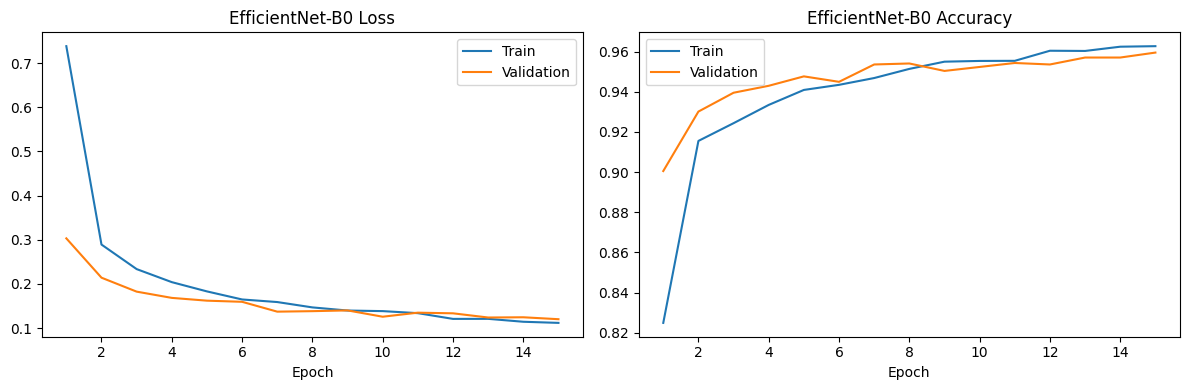

In [27]:
EFF_NUM_EPOCHS = 15
EFF_PATIENCE = 4
efficientnet_best_val_loss = float("inf")
efficientnet_best_epoch = 0
efficientnet_best_state = None
efficientnet_wait = 0
efficientnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

efficientnet_training_start = time.perf_counter()
for epoch in range(1, EFF_NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = run_model_epoch(
        efficientnet_model, train_loader, eff_criterion, eff_optimizer
    )
    val_loss, val_accuracy = run_model_epoch(
        efficientnet_model, val_loader, eff_criterion
    )

    efficientnet_history["train_loss"].append(train_loss)
    efficientnet_history["val_loss"].append(val_loss)
    efficientnet_history["train_accuracy"].append(train_accuracy)
    efficientnet_history["val_accuracy"].append(val_accuracy)

    if val_loss < efficientnet_best_val_loss:
        efficientnet_best_val_loss = val_loss
        efficientnet_best_epoch = epoch
        efficientnet_best_state = copy.deepcopy(efficientnet_model.state_dict())
        efficientnet_wait = 0
    else:
        efficientnet_wait += 1

    print(
        f"Epoch {epoch:02d}/{EFF_NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{time.perf_counter() - epoch_start:.1f}s"
    )
    if efficientnet_wait >= EFF_PATIENCE:
        print(f"Early stopping: validation loss did not improve for {EFF_PATIENCE} epochs.")
        break

efficientnet_training_seconds = time.perf_counter() - efficientnet_training_start
if efficientnet_best_state is None:
    raise RuntimeError("EfficientNet training did not produce a best validation checkpoint.")
efficientnet_model.load_state_dict(efficientnet_best_state)
print(
    f"Best epoch: {efficientnet_best_epoch} | "
    f"best validation loss: {efficientnet_best_val_loss:.4f} | "
    f"training time: {efficientnet_training_seconds:.1f}s"
)

eff_epochs = range(1, len(efficientnet_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(eff_epochs, efficientnet_history["train_loss"], label="Train")
axes[0].plot(eff_epochs, efficientnet_history["val_loss"], label="Validation")
axes[0].set(title="EfficientNet-B0 Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(eff_epochs, efficientnet_history["train_accuracy"], label="Train")
axes[1].plot(eff_epochs, efficientnet_history["val_accuracy"], label="Validation")
axes[1].set(title="EfficientNet-B0 Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 28. Save the Best EfficientNet-B0 Checkpoint

Save the validation-selected weights and the preprocessing/class metadata. The checkpoint is written only after the training cell has completed.

In [28]:
if efficientnet_best_state is None:
    raise RuntimeError("Run the EfficientNet training cell before saving its checkpoint.")

EFFICIENTNET_MODEL_PATH = Path("best_efficientnet_b0_eurosat.pth")
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_checkpoint = {
    "model_state_dict": {
        key: value.detach().cpu() for key, value in efficientnet_model.state_dict().items()
    },
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "best_epoch": efficientnet_best_epoch,
    "best_validation_loss": efficientnet_best_val_loss,
}
torch.save(efficientnet_checkpoint, EFFICIENTNET_MODEL_PATH)
print("Saved EfficientNet-B0 checkpoint:", EFFICIENTNET_MODEL_PATH.resolve())
print(f"Checkpoint size: {EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MiB")

Saved EfficientNet-B0 checkpoint: /content/best_efficientnet_b0_eurosat.pth
Checkpoint size: 15.61 MiB


## 29. EfficientNet-B0 Final Test Evaluation

Evaluate the validation-selected EfficientNet model on the held-out test loader. This is the final test evaluation for EfficientNet; do not use these results to tune it.

In [29]:
if efficientnet_best_state is None:
    raise RuntimeError("Run EfficientNet training before test evaluation.")
efficientnet_model.load_state_dict(efficientnet_best_state)
efficientnet_model.eval()

efficientnet_test_labels = []
efficientnet_test_predictions = []
efficientnet_test_probabilities = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = efficientnet_model(images)
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
        efficientnet_test_probabilities.extend(probabilities)
        efficientnet_test_predictions.extend(probabilities.argmax(axis=1))
        efficientnet_test_labels.extend(labels.numpy())

efficientnet_test_probabilities = np.asarray(efficientnet_test_probabilities)
efficientnet_test_accuracy = accuracy_score(
    efficientnet_test_labels, efficientnet_test_predictions
)
print(f"EfficientNet-B0 test accuracy: {efficientnet_test_accuracy:.4f}")
print("Test images:", len(efficientnet_test_labels))

EfficientNet-B0 test accuracy: 0.9605
Test images: 4050


## 30. EfficientNet Confusion Matrix and Classification Report

Inspect class-by-class test performance and the most frequent error patterns for EfficientNet-B0.

                      precision    recall  f1-score   support

          AnnualCrop     0.9903    0.9067    0.9466       450
              Forest     0.9634    0.9956    0.9792       450
HerbaceousVegetation     0.9573    0.9467    0.9520       450
             Highway     0.9539    0.9387    0.9462       375
          Industrial     0.9840    0.9867    0.9854       375
             Pasture     0.9117    0.9633    0.9368       300
       PermanentCrop     0.9100    0.9440    0.9267       375
         Residential     0.9739    0.9956    0.9846       450
               River     0.9475    0.9627    0.9550       375
             SeaLake     0.9954    0.9644    0.9797       450

            accuracy                         0.9605      4050
           macro avg     0.9588    0.9604    0.9592      4050
        weighted avg     0.9612    0.9605    0.9605      4050



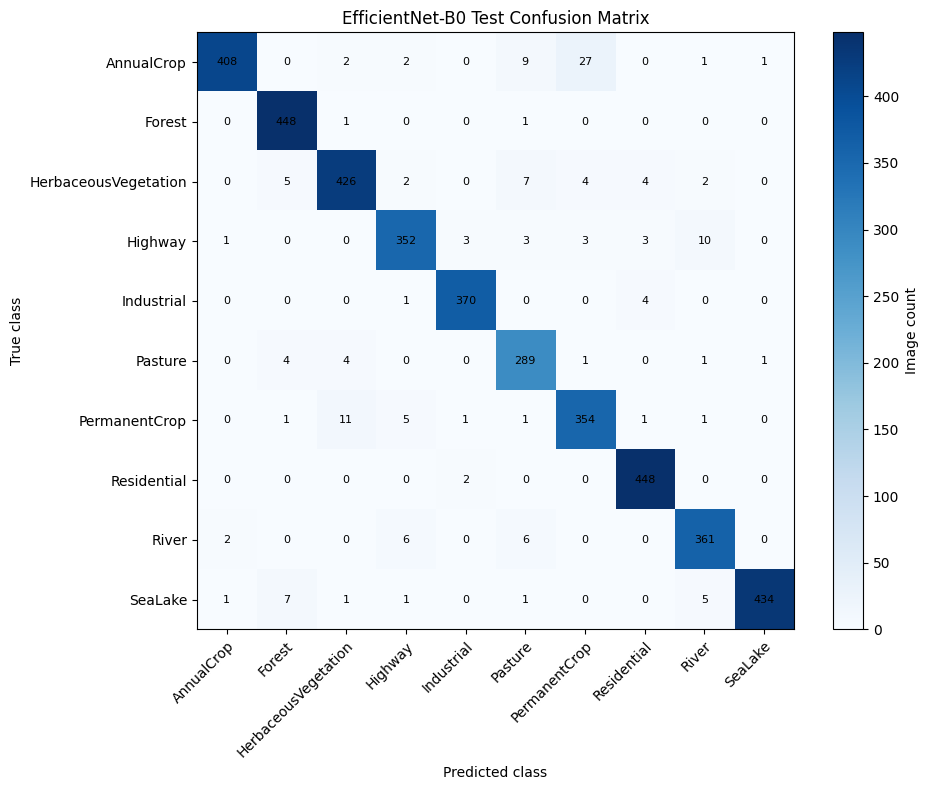

In [30]:
efficientnet_confusion = confusion_matrix(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
)
efficientnet_report_dict = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    digits=4,
    zero_division=0,
)
print(classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(efficientnet_confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EfficientNet-B0 Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(efficientnet_confusion[row, column]),
                ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 31. ResNet50 vs EfficientNet-B0 Comparison

Compare both models on the same held-out test set. The ResNet50 time is explicitly labeled approximate because the original notebook saved per-epoch times rounded to 0.1 seconds; EfficientNet time is measured with a timer. Checkpoint sizes are read from the saved files.

,Model,Test accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB)
0,ResNet50,0.9820,0.9811,0.9817,0.9814,103.3000,90.0526
1,EfficientNet-B0,0.9605,0.9588,0.9604,0.9592,144.4135,15.6094


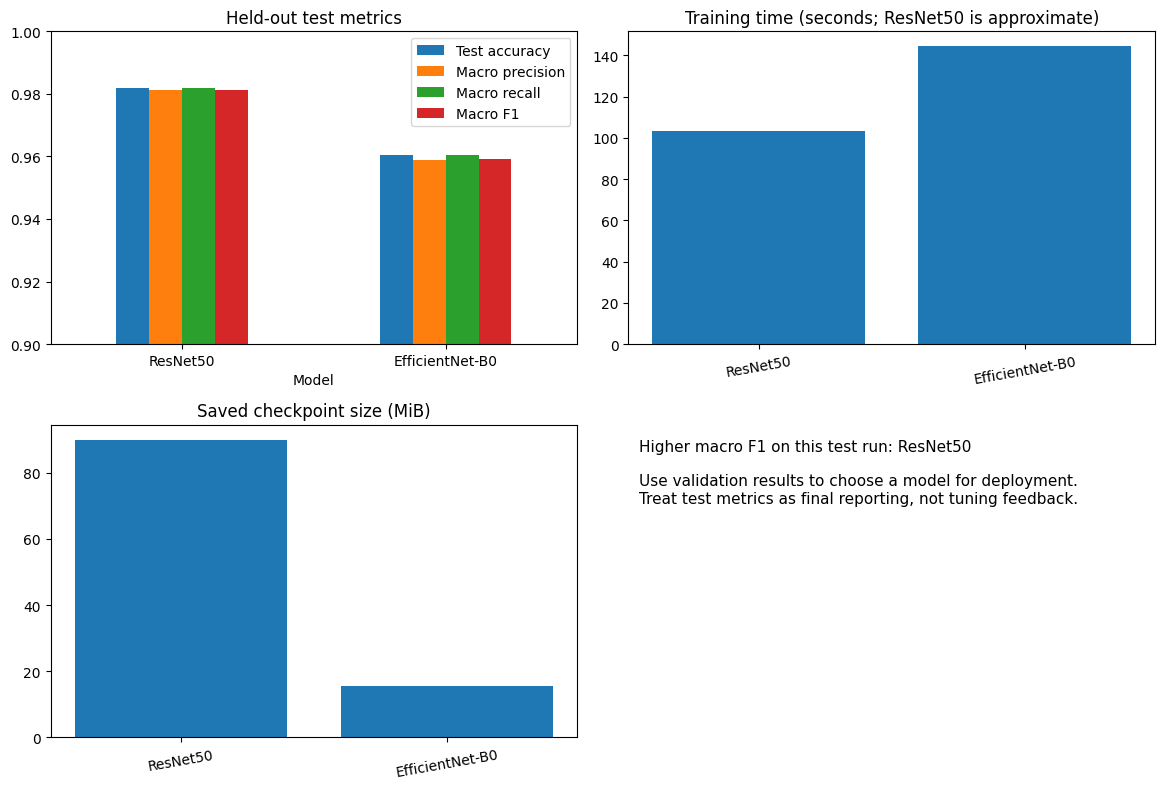

In [31]:
if not Path(MODEL_PATH).exists():
    raise FileNotFoundError("Run the ResNet50 model-saving cell before this comparison.")
if not Path(EFFICIENTNET_MODEL_PATH).exists():
    raise FileNotFoundError("Run the EfficientNet training and checkpoint cells first.")

efficientnet_report_for_comparison = classification_report(
    efficientnet_test_labels,
    efficientnet_test_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
model_comparison = pd.DataFrame([
    {
        "Model": "ResNet50",
        "Test accuracy": accuracy_score(all_labels, all_predictions),
        "Macro precision": baseline_report_dict["macro avg"]["precision"],
        "Macro recall": baseline_report_dict["macro avg"]["recall"],
        "Macro F1": baseline_report_dict["macro avg"]["f1-score"],
        "Training time (s)": baseline_training_seconds_approx,
        "Checkpoint size (MiB)": Path(MODEL_PATH).stat().st_size / (1024 ** 2),
    },
    {
        "Model": "EfficientNet-B0",
        "Test accuracy": efficientnet_test_accuracy,
        "Macro precision": efficientnet_report_for_comparison["macro avg"]["precision"],
        "Macro recall": efficientnet_report_for_comparison["macro avg"]["recall"],
        "Macro F1": efficientnet_report_for_comparison["macro avg"]["f1-score"],
        "Training time (s)": efficientnet_training_seconds,
        "Checkpoint size (MiB)": EFFICIENTNET_MODEL_PATH.stat().st_size / (1024 ** 2),
    },
])
display(model_comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metric_columns = ["Test accuracy", "Macro precision", "Macro recall", "Macro F1"]
model_comparison.set_index("Model")[metric_columns].plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Held-out test metrics")
axes[0, 0].set_ylim(0.90, 1.0)
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 1].bar(model_comparison["Model"], model_comparison["Training time (s)"])
axes[0, 1].set_title("Training time (seconds; ResNet50 is approximate)")
axes[0, 1].tick_params(axis="x", rotation=10)
axes[1, 0].bar(model_comparison["Model"], model_comparison["Checkpoint size (MiB)"])
axes[1, 0].set_title("Saved checkpoint size (MiB)")
axes[1, 0].tick_params(axis="x", rotation=10)
axes[1, 1].axis("off")
f1_winner = model_comparison.loc[model_comparison["Macro F1"].idxmax(), "Model"]
axes[1, 1].text(
    0.02, 0.75,
    f"Higher macro F1 on this test run: {f1_winner}\n\n"
    "Use validation results to choose a model for deployment.\n"
    "Treat test metrics as final reporting, not tuning feedback.",
    fontsize=11,
)
plt.tight_layout()
plt.show()

## 32. Per-Class Performance and Most Confused Classes

Compare per-class precision, recall, and F1, then list the largest off-diagonal errors. These tables explain which land-cover classes are hardest for each model.

In [32]:
baseline_confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
baseline_report_for_comparison = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

per_class_comparison = pd.DataFrame({
    "Class": class_names,
    "ResNet50 precision": [baseline_report_for_comparison[name]["precision"] for name in class_names],
    "ResNet50 recall": [baseline_report_for_comparison[name]["recall"] for name in class_names],
    "ResNet50 F1": [baseline_report_for_comparison[name]["f1-score"] for name in class_names],
    "EfficientNet precision": [efficientnet_report_for_comparison[name]["precision"] for name in class_names],
    "EfficientNet recall": [efficientnet_report_for_comparison[name]["recall"] for name in class_names],
    "EfficientNet F1": [efficientnet_report_for_comparison[name]["f1-score"] for name in class_names],
})
display(per_class_comparison.round(4))

def top_confusion_pairs(matrix, labels, top_n=5):
    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pairs = []
    for true_index, predicted_index in zip(*np.where(off_diagonal > 0)):
        pairs.append({
            "True class": labels[true_index],
            "Predicted as": labels[predicted_index],
            "Count": int(off_diagonal[true_index, predicted_index]),
        })
    if not pairs:
        return pd.DataFrame(columns=["True class", "Predicted as", "Count"])
    return pd.DataFrame(pairs).sort_values("Count", ascending=False).head(top_n)

print("ResNet50: most frequent confusion pairs")
display(top_confusion_pairs(baseline_confusion, class_names))
print("EfficientNet-B0: most frequent confusion pairs")
display(top_confusion_pairs(efficientnet_confusion, class_names))

,Class,ResNet50 precision,ResNet50 recall,ResNet50 F1,EfficientNet precision,EfficientNet recall,EfficientNet F1
0,AnnualCrop,0.9797,0.9644,0.9720,0.9903,0.9067,0.9466
1,Forest,0.9933,0.9956,0.9945,0.9634,0.9956,0.9792
2,HerbaceousVegetation,0.9647,0.9711,0.9679,0.9573,0.9467,0.9520
3,Highway,0.9789,0.9920,0.9854,0.9539,0.9387,0.9462
4,Industrial,0.9947,0.9947,0.9947,0.9840,0.9867,0.9854
5,Pasture,0.9577,0.9800,0.9687,0.9117,0.9633,0.9368
6,PermanentCrop,0.9649,0.9520,0.9584,0.9100,0.9440,0.9267
7,Residential,0.9956,0.9978,0.9967,0.9739,0.9956,0.9846
8,River,0.9839,0.9787,0.9813,0.9475,0.9627,0.9550
9,SeaLake,0.9978,0.9911,0.9944,0.9954,0.9644,0.9797


ResNet50: most frequent confusion pairs


,True class,Predicted as,Count
20,PermanentCrop,HerbaceousVegetation,10
2,AnnualCrop,Pasture,8
9,HerbaceousVegetation,PermanentCrop,6
3,AnnualCrop,PermanentCrop,6
19,PermanentCrop,AnnualCrop,5


EfficientNet-B0: most frequent confusion pairs


,True class,Predicted as,Count
3,AnnualCrop,PermanentCrop,27
28,PermanentCrop,HerbaceousVegetation,11
19,Highway,River,10
2,AnnualCrop,Pasture,9
10,HerbaceousVegetation,Pasture,7


## 33. Correct and Incorrect Prediction Examples with Confidence

Visualize representative ResNet50 predictions from the held-out test set. Confidence is the model's softmax score for its predicted class; it is not a guarantee that the prediction is correct.

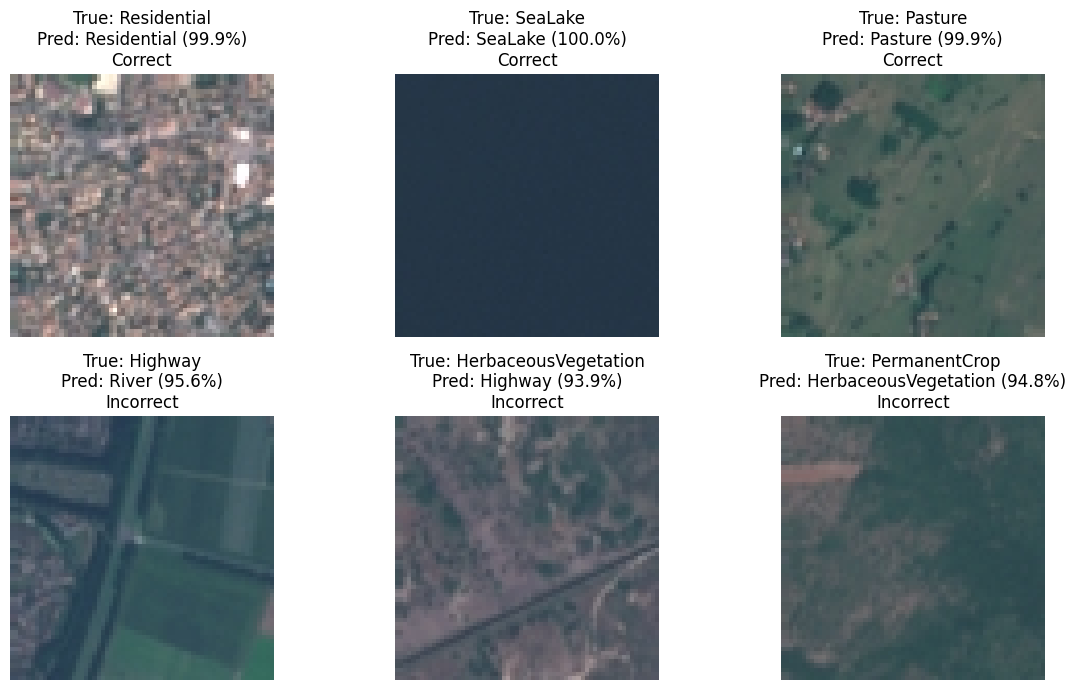

In [33]:
baseline_true_array = np.asarray(all_labels)
baseline_pred_array = np.asarray(all_predictions)
correct_positions = np.flatnonzero(baseline_true_array == baseline_pred_array)[:3]
incorrect_positions = np.flatnonzero(baseline_true_array != baseline_pred_array)[:3]
example_positions = list(correct_positions) + list(incorrect_positions)
if len(incorrect_positions) == 0:
    print("No incorrect test predictions are available to display.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(12, 7))
    axes = axes.ravel()
    for axis, test_position in zip(axes, example_positions):
        normalized_tensor, true_label = test_set[int(test_position)]
        original_dataset_index = test_set.indices[int(test_position)]
        original_image, _ = dataset[original_dataset_index]
        input_tensor = normalized_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            probabilities = torch.softmax(loaded_model(input_tensor), dim=1)[0]
        predicted_index = int(probabilities.argmax().item())
        confidence = float(probabilities[predicted_index].item())
        is_correct = predicted_index == int(true_label)
        axis.imshow(original_image)
        axis.set_title(
            f"True: {class_names[int(true_label)]}\n"
            f"Pred: {class_names[predicted_index]} ({confidence:.1%})\n"
            f"{'Correct' if is_correct else 'Incorrect'}"
        )
        axis.axis("off")
    for axis in axes[len(example_positions):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 34. Explainability with Grad-CAM

Grad-CAM uses gradients flowing into a final convolutional layer to create a coarse heatmap of image regions that support a chosen class score. The implementation below explains ResNet50 predictions, including one correct and one incorrect test example. Heatmaps are diagnostic visualizations, not proof of causal reasoning. [Original Grad-CAM paper](https://arxiv.org/abs/1610.02391).

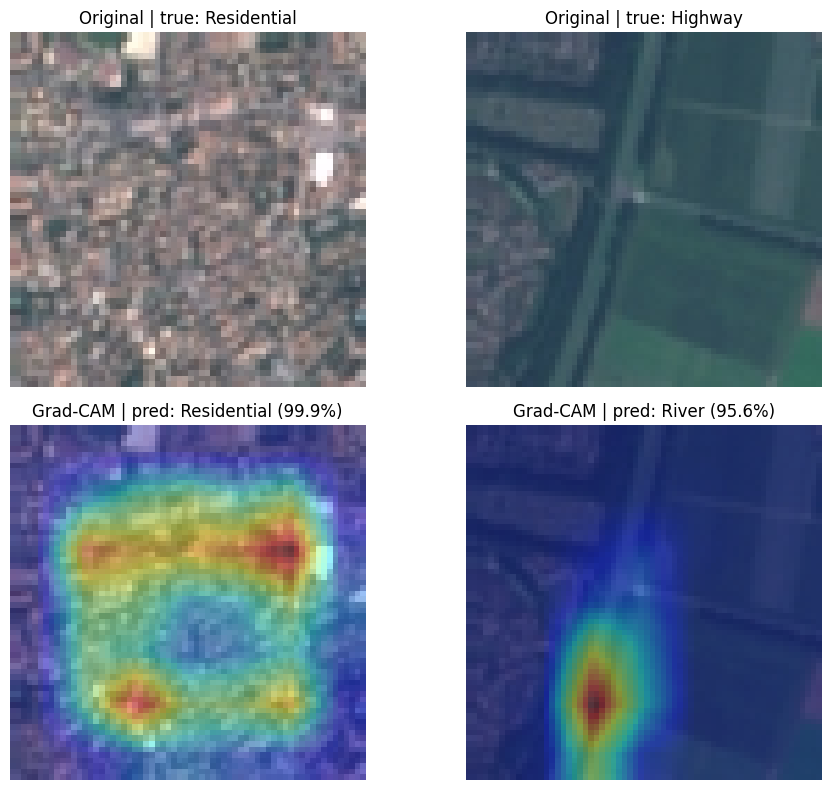

In [34]:
import torch.nn.functional as F

def generate_gradcam(model_to_explain, target_layer, image_tensor, output_size):
    activations = {}
    gradients = {}

    def capture_activation(module, inputs, output):
        activations["feature"] = output
        output.register_hook(lambda gradient: gradients.__setitem__("feature", gradient.detach()))

    hook_handle = target_layer.register_forward_hook(capture_activation)
    model_to_explain.eval()
    model_to_explain.zero_grad(set_to_none=True)
    input_batch = image_tensor.unsqueeze(0).to(device)
    logits = model_to_explain(input_batch)
    predicted_index = int(logits.argmax(dim=1).item())
    score = logits[:, predicted_index].sum()
    score.backward()
    hook_handle.remove()

    feature_maps = activations["feature"].detach()
    feature_gradients = gradients["feature"]
    channel_weights = feature_gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((channel_weights * feature_maps).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=output_size, mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / cam.max().clamp_min(1e-8)
    confidence = torch.softmax(logits.detach(), dim=1)[0, predicted_index].item()
    return predicted_index, confidence, cam.cpu().numpy()

if len(correct_positions) == 0 or len(incorrect_positions) == 0:
    raise RuntimeError("Grad-CAM examples require at least one correct and one incorrect test prediction.")

gradcam_positions = [int(correct_positions[0]), int(incorrect_positions[0])]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for column, test_position in enumerate(gradcam_positions):
    normalized_tensor, true_label = test_set[test_position]
    original_dataset_index = test_set.indices[test_position]
    original_image, _ = dataset[original_dataset_index]
    heatmap_size = (original_image.height, original_image.width)
    predicted_index, confidence, heatmap = generate_gradcam(
        loaded_model, loaded_model.layer4, normalized_tensor, heatmap_size
    )
    axes[0, column].imshow(original_image)
    axes[0, column].set_title(f"Original | true: {class_names[int(true_label)]}")
    axes[1, column].imshow(original_image)
    axes[1, column].imshow(heatmap, cmap="jet", alpha=0.40)
    axes[1, column].set_title(
        f"Grad-CAM | pred: {class_names[predicted_index]} ({confidence:.1%})"
    )
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()

## 35. Multispectral EuroSAT: Separate Extension Plan

The current model uses three RGB channels. The original EuroSAT release also provides EuroSAT_MS.zip with all 13 Sentinel-2 bands in their original value range; these must be treated as a separate dataset and preprocessing pipeline. Sentinel-2 bands have native 10 m, 20 m, or 60 m resolutions, so alignment and per-band scaling must be checked before training. Sources: [EuroSAT paper](https://arxiv.org/abs/1709.00029), [EuroSAT Zenodo record](https://zenodo.org/records/7711097), and [Sentinel-2 product specification](https://sentinels.copernicus.eu/documents/d/sentinel/sentinel-2-products-specification-document-15_1).

In [35]:
multispectral_comparison = pd.DataFrame([
    {"Input": "RGB EuroSAT", "Channels": 3, "Typical tensor": "[B, 3, 64, 64] before resize", "Preprocessing": "RGB conversion, ImageNet normalization"},
    {"Input": "EuroSAT multispectral", "Channels": 13, "Typical tensor": "[B, 13, 64, 64]", "Preprocessing": "Align bands; inspect original range; normalize each band using training data only"},
])
display(multispectral_comparison)

sentinel_band_groups = pd.DataFrame([
    {"Native resolution": "10 m", "Sentinel-2 bands": "B2, B3, B4, B8"},
    {"Native resolution": "20 m", "Sentinel-2 bands": "B5, B6, B7, B8A, B11, B12"},
    {"Native resolution": "60 m", "Sentinel-2 bands": "B1, B9, B10"},
])
display(sentinel_band_groups)

def adapt_resnet50_first_layer_to_13_bands(num_classes=NUM_CLASSES, num_bands=13):
    """Create a separate 13-channel ResNet50; this does not modify either RGB model."""
    multispectral_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    old_conv = multispectral_model.conv1
    new_conv = nn.Conv2d(
        in_channels=num_bands,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )
    with torch.no_grad():
        mean_rgb_kernel = old_conv.weight.mean(dim=1, keepdim=True)
        new_conv.weight.copy_(mean_rgb_kernel.repeat(1, num_bands, 1, 1) * (3 / num_bands))
    multispectral_model.conv1 = new_conv
    multispectral_model.fc = nn.Linear(multispectral_model.fc.in_features, num_classes)
    return multispectral_model

print("The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.")

,Input,Channels,Typical tensor,Preprocessing
0,RGB EuroSAT,3,"[B, 3, 64, 64] before resize","RGB conversion, ImageNet normalization"
1,EuroSAT multispectral,13,"[B, 13, 64, 64]",Align bands; inspect original range; normalize...


,Native resolution,Sentinel-2 bands
0,10 m,"B2, B3, B4, B8"
1,20 m,"B5, B6, B7, B8A, B11, B12"
2,60 m,"B1, B9, B10"


The 13-band model factory is defined but not called; no multispectral data is mixed into RGB training.


## 36. Practical Optimization Options

The existing pipelines already use transfer learning, early stopping, and best-checkpoint selection. For a new controlled experiment, reduce the learning rate when validation loss plateaus; apply the same policy to both architectures if comparing them. Tune only on the validation set, never on test results.

In [36]:
def make_validation_lr_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    )

# Optional for a future training run:
# scheduler = make_validation_lr_scheduler(optimizer)
# After each validation epoch, call: scheduler.step(val_loss)
# Keep this experiment separate from the already-reported baseline results.

optimization_experiments = pd.DataFrame([
    {"Experiment": "Learning-rate schedule", "Selection data": "Validation", "Purpose": "Reduce learning rate after a validation-loss plateau"},
    {"Experiment": "Unfreeze more/less layers", "Selection data": "Validation", "Purpose": "Trade adaptation capacity against compute and overfitting"},
    {"Experiment": "Batch size / learning rate", "Selection data": "Validation", "Purpose": "Measure stability and GPU memory use"},
])
display(optimization_experiments)

,Experiment,Selection data,Purpose
0,Learning-rate schedule,Validation,Reduce learning rate after a validation-loss p...
1,Unfreeze more/less layers,Validation,Trade adaptation capacity against compute and ...
2,Batch size / learning rate,Validation,Measure stability and GPU memory use


## 37. Inference Speed Measurement

Measure single-image inference after warm-up for both trained models on the same device. This is a runtime benchmark, not a change to model weights or test-set metrics.

In [37]:
def benchmark_single_image(model_to_benchmark, image_tensor, warmup=10, iterations=50):
    model_to_benchmark.eval()
    input_batch = image_tensor.unsqueeze(0).to(device)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_time = time.perf_counter()
        for _ in range(iterations):
            _ = model_to_benchmark(input_batch)
        if device.type == "cuda":
            torch.cuda.synchronize()
    average_ms = (time.perf_counter() - start_time) * 1000 / iterations
    return average_ms

benchmark_image, _ = test_set[0]
speed_results = pd.DataFrame([
    {"Model": "ResNet50", "Average single-image latency (ms)": benchmark_single_image(loaded_model, benchmark_image)},
    {"Model": "EfficientNet-B0", "Average single-image latency (ms)": benchmark_single_image(efficientnet_model, benchmark_image)},
])
speed_results["Images per second (approx.)"] = 1000 / speed_results["Average single-image latency (ms)"]
display(speed_results.round(2))

,Model,Average single-image latency (ms),Images per second (approx.)
0,ResNet50,1.6,626.67
1,EfficientNet-B0,2.0,500.28


# Phase 3 — EuroSAT Multispectral Classification

This phase adds a separate 13-band Sentinel-2 pipeline after the completed RGB work above. The source is the official [EuroSAT Zenodo record](https://zenodo.org/records/7711810); use the file named EuroSAT_MS.zip. It contains multispectral GeoTIFFs, not the RGB JPEG archive. The dataset has 10 land-cover classes and 27,000 labeled image patches ([EuroSAT paper](https://arxiv.org/abs/1709.00029)).

RGB stores three visible-color channels. Multispectral imagery stores measurements from 13 wavelength bands, including red-edge, near-infrared, water-vapor, cirrus, and short-wave infrared information. These are physical sensor measurements, so RGB/ImageNet normalization is not suitable for the 13-band input.

All new cells are intentionally unexecuted. Run them in order when ready. The download is about 2.1 GB, and the training cell is a manual step.


## 41. Baseline and Class Mapping

The original cells and results remain intact. This section reuses their 10-class order and, when TIFF and RGB filenames correspond exactly, the same train/validation/test sample split. Otherwise the multispectral pipeline creates a fixed-seed stratified 70/15/15 split.

Expected output: the existing class names and the 18,900 / 4,050 / 4,050 RGB split sizes.


In [38]:
# Use the class mapping and split already established by the RGB notebook.
if "class_names" not in globals() or "targets" not in globals():
    raise RuntimeError("Run the original RGB data-loading and split cells before this multispectral phase.")
if "dataset" not in globals() or not hasattr(dataset, "samples"):
    raise RuntimeError("The original EuroSAT RGB ImageFolder dataset is required for class/split matching.")

MS_CLASS_NAMES = list(class_names)
MS_CLASS_TO_IDX = {name: index for index, name in enumerate(MS_CLASS_NAMES)}
MS_NUM_CLASSES = len(MS_CLASS_NAMES)
EUROSAT_MS_BAND_ORDER = [
    "B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08",
    "B09", "B10", "B11", "B12", "B8A",
]
assert MS_NUM_CLASSES == 10, f"Expected 10 classes, found {MS_NUM_CLASSES}."
assert len(EUROSAT_MS_BAND_ORDER) == 13

if hasattr(dataset, "class_to_idx"):
    assert dataset.class_to_idx == MS_CLASS_TO_IDX, (
        "The RGB class order differs from the existing class_names mapping."
    )

print("RGB class mapping reused:")
for class_name, class_index in MS_CLASS_TO_IDX.items():
    print(f"  {class_index}: {class_name}")
print("RGB split sizes:", len(train_indices), len(val_indices), len(test_indices))
print("EuroSAT MS band order:", ", ".join(EUROSAT_MS_BAND_ORDER))


RGB class mapping reused:
  0: AnnualCrop
  1: Forest
  2: HerbaceousVegetation
  3: Highway
  4: Industrial
  5: Pasture
  6: PermanentCrop
  7: Residential
  8: River
  9: SeaLake
RGB split sizes: 18900 4050 4050
EuroSAT MS band order: B01, B02, B03, B04, B05, B06, B07, B08, B09, B10, B11, B12, B8A


## 42. Rasterio Setup

Rasterio opens GeoTIFFs as band-first arrays with shape (bands, rows, columns). The code below checks band count and metadata directly from each TIFF rather than treating the multispectral archive as RGB.

Expected output: Rasterio version and the canonical 13-channel band order.


In [39]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

import rasterio
print("Rasterio version:", rasterio.__version__)
print("A Rasterio read is organized as (bands, rows, columns).")


Rasterio version: 1.5.2
A Rasterio read is organized as (bands, rows, columns).


## 43. Download the Official Multispectral Archive

The correct Zenodo asset is EuroSAT_MS.zip (MD5: 091174add3c8e680a49244acf185b9f0). The download cell verifies that checksum before extraction and rejects unsafe archive paths.

Expected output: a verified archive and the discovered folder containing the 10 class subfolders.


In [40]:
import hashlib
import os
import zipfile
from pathlib import Path

import requests

MS_DOWNLOAD_URL = "https://zenodo.org/records/7711810/files/EuroSAT_MS.zip?download=1"
MS_EXPECTED_MD5 = "091174add3c8e680a49244acf185b9f0"
MS_WORK_DIR = Path("/content/eurosat_multispectral")
MS_WORK_DIR.mkdir(parents=True, exist_ok=True)
MS_ZIP_PATH = MS_WORK_DIR / "EuroSAT_MS.zip"
MS_EXTRACT_DIR = MS_WORK_DIR / "extracted"

if not MS_ZIP_PATH.exists():
    partial_path = MS_ZIP_PATH.with_suffix(".zip.part")
    print("Downloading EuroSAT_MS.zip from Zenodo (approximately 2.1 GB)...")
    with requests.get(MS_DOWNLOAD_URL, stream=True, timeout=(60, 300)) as response:
        response.raise_for_status()
        total_bytes = int(response.headers.get("content-length", 0))
        downloaded_bytes = 0
        last_reported_mb = -1
        with partial_path.open("wb") as output_file:
            for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                if not chunk:
                    continue
                output_file.write(chunk)
                downloaded_bytes += len(chunk)
                downloaded_mb = downloaded_bytes // (1024 * 1024)
                if downloaded_mb // 100 != last_reported_mb // 100:
                    total_text = f" / {total_bytes // (1024 * 1024):,} MiB" if total_bytes else ""
                    print(f"Downloaded {downloaded_mb:,} MiB{total_text}")
                    last_reported_mb = downloaded_mb
    os.replace(partial_path, MS_ZIP_PATH)

md5 = hashlib.md5()
with MS_ZIP_PATH.open("rb") as archive_file:
    for chunk in iter(lambda: archive_file.read(8 * 1024 * 1024), b""):
        md5.update(chunk)
actual_md5 = md5.hexdigest()
if actual_md5.lower() != MS_EXPECTED_MD5:
    raise ValueError(
        f"EuroSAT MS checksum mismatch: expected {MS_EXPECTED_MD5}, got {actual_md5}"
    )
print(f"Verified archive checksum: {actual_md5}")

archive_has_tiffs = (
    any(path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
        for path in MS_EXTRACT_DIR.rglob("*"))
    if MS_EXTRACT_DIR.exists() else False
)
if not archive_has_tiffs:
    MS_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(MS_ZIP_PATH) as archive:
        unsafe_members = [
            member.filename for member in archive.infolist()
            if Path(member.filename).is_absolute() or ".." in Path(member.filename).parts
        ]
        if unsafe_members:
            raise ValueError(f"Unsafe path found in archive: {unsafe_members[:3]}")
        archive.extractall(MS_EXTRACT_DIR)

candidate_class_dirs = [
    path for path in MS_EXTRACT_DIR.rglob(MS_CLASS_NAMES[0])
    if path.is_dir()
    and all((path.parent / class_name).is_dir() for class_name in MS_CLASS_NAMES)
]
if not candidate_class_dirs:
    raise FileNotFoundError(
        "Could not find a directory containing all expected EuroSAT class folders."
    )
MS_CLASS_ROOT = sorted(candidate_class_dirs, key=lambda path: len(path.parts))[0].parent
print("Multispectral class root:", MS_CLASS_ROOT)


Downloaded 8 MiB / 1,969 MiB
Downloaded 104 MiB / 1,969 MiB
Downloaded 200 MiB / 1,969 MiB
Downloaded 304 MiB / 1,969 MiB
Downloaded 400 MiB / 1,969 MiB
Downloaded 504 MiB / 1,969 MiB
Downloaded 600 MiB / 1,969 MiB
Downloaded 704 MiB / 1,969 MiB
Downloaded 800 MiB / 1,969 MiB
Downloaded 904 MiB / 1,969 MiB
Downloaded 1,000 MiB / 1,969 MiB
Downloaded 1,104 MiB / 1,969 MiB
Downloaded 1,200 MiB / 1,969 MiB
Downloaded 1,304 MiB / 1,969 MiB
Downloaded 1,400 MiB / 1,969 MiB
Downloaded 1,504 MiB / 1,969 MiB
Downloaded 1,600 MiB / 1,969 MiB
Downloaded 1,704 MiB / 1,969 MiB
Downloaded 1,800 MiB / 1,969 MiB
Downloaded 1,904 MiB / 1,969 MiB
Verified archive checksum: 091174add3c8e680a49244acf185b9f0
Multispectral class root: /content/eurosat_multispectral/extracted/EuroSAT_MS


## 44. Inspect TIFF Structure, Labels, and Values

The notebook inventories every TIFF's class, dimensions, number of bands, and dtype. It reads a small reproducible class-balanced sample to report pixel ranges; the sample range is explicitly labeled as a sample, while class counts and structural checks cover the full archive.

Expected output: 27,000 TIFFs, 13 bands per image, dimension/dtype counts, class distribution, and sampled per-band ranges.


In [41]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

import rasterio
from collections import Counter
import numpy as np
import pandas as pd

MS_RECORDS = []

for class_name in MS_CLASS_NAMES:
    class_dir = MS_CLASS_ROOT / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(f"Missing class directory: {class_dir}")

    class_paths = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
    )

    for path in class_paths:
        MS_RECORDS.append({
            "path": path,
            "class_name": class_name,
            "label": MS_CLASS_TO_IDX[class_name],
        })

if not MS_RECORDS:
    raise RuntimeError("No TIFF images found in the EuroSAT MS class folders.")

metadata_rows = []
invalid_band_files = []

for record in MS_RECORDS:
    with rasterio.open(record["path"]) as src:
        row = {
            "class": record["class_name"],
            "path": str(record["path"]),
            "width": src.width,
            "height": src.height,
            "band_count": src.count,
            "dtypes": ",".join(src.dtypes),
            "nodata": str(src.nodatavals),
            "descriptions": str(src.descriptions),
        }
        metadata_rows.append(row)

        if src.count != 13:
            invalid_band_files.append((str(record["path"]), src.count))

if invalid_band_files:
    raise ValueError(
        f"Found TIFFs without exactly 13 bands; examples: {invalid_band_files[:5]}"
    )

MS_METADATA = pd.DataFrame(metadata_rows)

MS_CLASS_COUNTS = Counter(record["class_name"] for record in MS_RECORDS)
MS_CLASS_DISTRIBUTION = pd.DataFrame({
    "Class": MS_CLASS_NAMES,
    "Images": [MS_CLASS_COUNTS[name] for name in MS_CLASS_NAMES],
})

print(f"Total multispectral TIFFs: {len(MS_RECORDS):,}")
print(
    "Unique dimensions:",
    sorted(set(zip(MS_METADATA["width"], MS_METADATA["height"])))
)
print("Band counts:", MS_METADATA["band_count"].value_counts().to_dict())

print("Dtype profiles:")
display(
    MS_METADATA.groupby(["dtypes", "band_count"])
    .size()
    .rename("files")
    .to_frame()
)

print("Class distribution:")
display(MS_CLASS_DISTRIBUTION)

rng = np.random.default_rng(int(globals().get("SEED", 42)))
sample_indices = []

for class_name in MS_CLASS_NAMES:
    indices = [
        i for i, record in enumerate(MS_RECORDS)
        if record["class_name"] == class_name
    ]

    sample_indices.extend(
        rng.choice(
            indices,
            size=min(3, len(indices)),
            replace=False
        ).tolist()
    )

sample_min = np.full(13, np.inf, dtype=np.float64)
sample_max = np.full(13, -np.inf, dtype=np.float64)

sample_descriptions = None
sample_dtypes = None
sample_nodata = None

for index in sample_indices:
    with rasterio.open(MS_RECORDS[index]["path"]) as src:
        data = src.read(out_dtype="float32")
        sample_descriptions = src.descriptions
        sample_dtypes = src.dtypes
        sample_nodata = src.nodatavals

        valid = np.isfinite(data) & (src.read_masks() > 0)

        for band_index, nodata_value in enumerate(src.nodatavals):
            if nodata_value is not None and np.isfinite(nodata_value):
                valid[band_index] &= data[band_index] != nodata_value

        # Treat a pixel as invalid only when all 13 band values are zero.
        valid &= ~np.all(data == 0, axis=0)[None, :, :]

        for band_index in range(13):
            values = data[band_index][valid[band_index]]

            if values.size:
                sample_min[band_index] = min(
                    sample_min[band_index],
                    float(values.min())
                )
                sample_max[band_index] = max(
                    sample_max[band_index],
                    float(values.max())
                )

MS_RANGE_SAMPLE = pd.DataFrame({
    "Band (official TIFF order)": EUROSAT_MS_BAND_ORDER,
    "Sample minimum": sample_min,
    "Sample maximum": sample_max,
})

print(
    f"Value ranges below come from "
    f"{len(sample_indices)} class-balanced TIFF samples:"
)
display(MS_RANGE_SAMPLE)

print("Example TIFF dtype:", sample_dtypes)
print("Example TIFF descriptions:", sample_descriptions)
print("Example TIFF nodata values:", sample_nodata)

Total multispectral TIFFs: 27,000
Unique dimensions: [(64, 64)]
Band counts: {13: 27000}
Dtype profiles:


,,files
dtypes,band_count,
"uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16",13,27000


Class distribution:


,Class,Images
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


Value ranges below come from 30 class-balanced TIFF samples:


,Band (official TIFF order),Sample minimum,Sample maximum
0,B01,1035.0,2734.0
1,B02,686.0,6605.0
2,B03,441.0,7175.0
3,B04,233.0,9926.0
4,B05,238.0,5826.0
5,B06,217.0,6424.0
6,B07,205.0,7149.0
7,B08,157.0,9606.0
8,B09,51.0,2099.0
9,B10,4.0,41.0


Example TIFF dtype: ('uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16', 'uint16')
Example TIFF descriptions: (None, None, None, None, None, None, None, None, None, None, None, None, None)
Example TIFF nodata values: (None, None, None, None, None, None, None, None, None, None, None, None, None)


## 45. Reuse or Create a Stratified Split

Exact sample correspondence is checked using (class folder, filename stem) keys from the existing RGB dataset and the MS TIFFs. If all keys and labels match, the original RGB indices define all three MS subsets. If not, the code creates a reproducible stratified 70/15/15 split using the existing SEED.

Expected output: split mode, sample counts, and per-class train/validation/test counts. The test subset remains held out.


In [42]:
from sklearn.model_selection import train_test_split

MS_LABELS = np.asarray([record["label"] for record in MS_RECORDS], dtype=np.int64)
MS_KEYS = [
    (record["class_name"], record["path"].stem)
    for record in MS_RECORDS
]
if len(set(MS_KEYS)) != len(MS_KEYS):
    raise ValueError("Duplicate (class, filename stem) keys found in the MS archive.")

rgb_samples = list(dataset.samples)
rgb_key_to_index = {}
for rgb_index, (rgb_path, rgb_label) in enumerate(rgb_samples):
    rgb_class = MS_CLASS_NAMES[int(rgb_label)]
    key = (rgb_class, Path(rgb_path).stem)
    if key in rgb_key_to_index:
        raise ValueError(f"Duplicate RGB sample key: {key}")
    rgb_key_to_index[key] = rgb_index

ms_key_to_index = {key: index for index, key in enumerate(MS_KEYS)}
same_samples = set(rgb_key_to_index) == set(ms_key_to_index)
same_labels = same_samples and all(
    int(MS_LABELS[ms_key_to_index[key]]) == int(dataset.samples[rgb_key_to_index[key]][1])
    for key in rgb_key_to_index
)

if same_samples and same_labels and all(
    name in globals() for name in ("train_indices", "val_indices", "test_indices")
):
    rgb_split_by_index = {}
    for split_name, indices in (
        ("train", train_indices),
        ("validation", val_indices),
        ("test", test_indices),
    ):
        for rgb_index in np.asarray(indices, dtype=np.int64):
            rgb_split_by_index[int(rgb_index)] = split_name
    MS_TRAIN_INDICES, MS_VAL_INDICES, MS_TEST_INDICES = [], [], []
    for ms_index, key in enumerate(MS_KEYS):
        rgb_index = rgb_key_to_index[key]
        split_name = rgb_split_by_index[rgb_index]
        if split_name == "train":
            MS_TRAIN_INDICES.append(ms_index)
        elif split_name == "validation":
            MS_VAL_INDICES.append(ms_index)
        else:
            MS_TEST_INDICES.append(ms_index)
    MS_SPLIT_MODE = "same RGB samples and same RGB split (filename/class keys matched)"
else:
    ms_all_indices = np.arange(len(MS_RECORDS))
    test_count = int(round(0.15 * len(ms_all_indices)))
    val_count = int(round(0.15 * len(ms_all_indices)))
    seed = int(globals().get("SEED", 42))
    ms_train_val, MS_TEST_INDICES = train_test_split(
        ms_all_indices,
        test_size=test_count,
        random_state=seed,
        stratify=MS_LABELS,
    )
    MS_TRAIN_INDICES, MS_VAL_INDICES = train_test_split(
        ms_train_val,
        test_size=val_count,
        random_state=seed,
        stratify=MS_LABELS[ms_train_val],
    )
    MS_SPLIT_MODE = "independent reproducible stratified 70/15/15 split"

MS_TRAIN_INDICES = np.asarray(MS_TRAIN_INDICES, dtype=np.int64)
MS_VAL_INDICES = np.asarray(MS_VAL_INDICES, dtype=np.int64)
MS_TEST_INDICES = np.asarray(MS_TEST_INDICES, dtype=np.int64)
assert not (set(MS_TRAIN_INDICES) & set(MS_VAL_INDICES))
assert not (set(MS_TRAIN_INDICES) & set(MS_TEST_INDICES))
assert not (set(MS_VAL_INDICES) & set(MS_TEST_INDICES))
assert len(MS_TRAIN_INDICES) + len(MS_VAL_INDICES) + len(MS_TEST_INDICES) == len(MS_RECORDS)

MS_SPLIT_SUMMARY = pd.DataFrame({
    "Class": MS_CLASS_NAMES,
    "Train": np.bincount(MS_LABELS[MS_TRAIN_INDICES], minlength=MS_NUM_CLASSES),
    "Validation": np.bincount(MS_LABELS[MS_VAL_INDICES], minlength=MS_NUM_CLASSES),
    "Test": np.bincount(MS_LABELS[MS_TEST_INDICES], minlength=MS_NUM_CLASSES),
})
print("Multispectral split:", MS_SPLIT_MODE)
print(
    f"Train: {len(MS_TRAIN_INDICES):,} | "
    f"Validation: {len(MS_VAL_INDICES):,} | Test: {len(MS_TEST_INDICES):,}"
)
display(MS_SPLIT_SUMMARY)


Multispectral split: same RGB samples and same RGB split (filename/class keys matched)
Train: 18,900 | Validation: 4,050 | Test: 4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 46. TIFF Loader and Training-Only Band Statistics

Invalid pixels are identified from non-finite values, Rasterio masks, explicit per-band nodata values, and pixels that are zero in every band. Individual zero values are kept when the pixel has other valid measurements. Per-band mean and standard deviation are accumulated from training TIFFs only; validation and test data do not contribute.

Expected output: the 13 training-only means and standard deviations. These are recomputed from the current training split, not copied from a published dataset statistic.


In [43]:
import re

def _band_name_from_description(description):
    if not description:
        return None
    match = re.search(r"B(?:0[1-9]|1[0-2]|8A)", str(description).upper())
    return match.group(0) if match else None

def read_eurosat_ms(path):
    with rasterio.open(path) as src:
        if src.count != 13:
            raise ValueError(f"{path} has {src.count} bands, expected 13.")
        data = src.read(out_dtype="float32")
        nodata_values = list(src.nodatavals)
        masks = src.read_masks()
        descriptions = list(src.descriptions)

    described_bands = [_band_name_from_description(value) for value in descriptions]
    if all(described_bands):
        if set(described_bands) != set(EUROSAT_MS_BAND_ORDER):
            raise ValueError(f"Unexpected named bands in {path}: {described_bands}")
        order = [described_bands.index(name) for name in EUROSAT_MS_BAND_ORDER]
        data = data[order]
        masks = masks[order]
        nodata_values = [nodata_values[index] for index in order]
    elif any(described_bands):
        raise ValueError(
            f"TIFF contains only partial band-name metadata: {descriptions}"
        )
    # If descriptions are absent, use EuroSAT's official stored order:
    # B01-B08, B09-B12, B8A. See the band-order discussion linked above.
    return data, nodata_values, masks

def valid_ms_pixels(data, nodata_values, masks):
    valid = np.isfinite(data) & (masks > 0)
    for band_index, nodata_value in enumerate(nodata_values):
        if nodata_value is not None and np.isfinite(nodata_value):
            valid[band_index] &= data[band_index] != nodata_value
    valid &= ~np.all(data == 0, axis=0)[None, :, :]
    return valid

band_sum = np.zeros(13, dtype=np.float64)
band_sum_sq = np.zeros(13, dtype=np.float64)
band_valid_count = np.zeros(13, dtype=np.int64)

for count, record_index in enumerate(MS_TRAIN_INDICES, start=1):
    record = MS_RECORDS[int(record_index)]
    data, nodata_values, masks = read_eurosat_ms(record["path"])
    valid = valid_ms_pixels(data, nodata_values, masks)
    for band_index in range(13):
        values = data[band_index][valid[band_index]].astype(np.float64, copy=False)
        if values.size:
            band_sum[band_index] += values.sum(dtype=np.float64)
            band_sum_sq[band_index] += np.square(values).sum(dtype=np.float64)
            band_valid_count[band_index] += values.size
    if count % 3000 == 0 or count == len(MS_TRAIN_INDICES):
        print(f"Scanned training rasters: {count:,}/{len(MS_TRAIN_INDICES):,}")

if np.any(band_valid_count == 0):
    raise ValueError("At least one band has no valid training pixels.")

MS_BAND_MEAN = band_sum / band_valid_count
MS_BAND_VARIANCE = np.maximum(band_sum_sq / band_valid_count - MS_BAND_MEAN ** 2, 0.0)
MS_BAND_STD = np.sqrt(MS_BAND_VARIANCE)
MS_BAND_STD = np.maximum(MS_BAND_STD, 1e-6)

MS_NORMALIZATION = pd.DataFrame({
    "Band": EUROSAT_MS_BAND_ORDER,
    "Training mean": MS_BAND_MEAN,
    "Training std": MS_BAND_STD,
    "Valid training pixels": band_valid_count,
})
display(MS_NORMALIZATION.round(4))
print("Statistics used only MS_TRAIN_INDICES:", len(MS_TRAIN_INDICES), "images")


Scanned training rasters: 3,000/18,900
Scanned training rasters: 6,000/18,900
Scanned training rasters: 9,000/18,900
Scanned training rasters: 12,000/18,900
Scanned training rasters: 15,000/18,900
Scanned training rasters: 18,000/18,900
Scanned training rasters: 18,900/18,900


,Band,Training mean,Training std,Valid training pixels
0,B01,1355.1663,245.1208,77414400
1,B02,1118.4997,333.4460,77414400
2,B03,1042.5182,395.3290,77414400
3,B04,947.5843,594.8730,77414400
4,B05,1199.3508,568.0429,77414400
5,B06,2000.3326,861.1387,77414400
6,B07,2370.4347,1086.5859,77414400
7,B08,2297.6891,1117.9311,77414400
8,B09,729.8927,402.5253,77414400
9,B10,12.0998,4.7761,77414400


Statistics used only MS_TRAIN_INDICES: 18900 images


## 47. PyTorch Dataset and DataLoaders

Each item reads its GeoTIFF with Rasterio, normalizes with the training-only statistics, and returns a 13×224×224 tensor. The 64×64 EuroSAT patches are resized to 224×224 to match the RGB experiment's ResNet input pipeline. Train-only flips and right-angle rotations are label-preserving augmentations.

Expected output: a batch shaped (batch, 13, 224, 224) and integer labels.


In [44]:
import random
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

MS_IMAGE_SIZE = int(globals().get("IMAGE_SIZE", 224))
MS_BATCH_SIZE = int(globals().get("BATCH_SIZE", 32))
MS_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MS_NUM_WORKERS = 2 if MS_DEVICE.type == "cuda" else 0

class EuroSATMultispectralDataset(Dataset):
    def __init__(self, records, indices, mean, std, image_size=224, augment=False):
        self.records = records
        self.indices = np.asarray(indices, dtype=np.int64)
        self.mean = np.asarray(mean, dtype=np.float32)[:, None, None]
        self.std = np.asarray(std, dtype=np.float32)[:, None, None]
        self.image_size = int(image_size)
        self.augment = bool(augment)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        record = self.records[int(self.indices[item])]
        data, nodata_values, masks = read_eurosat_ms(record["path"])
        valid = valid_ms_pixels(data, nodata_values, masks)
        safe_data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)
        safe_data[~valid] = np.broadcast_to(self.mean, safe_data.shape)[~valid]
        normalized = (safe_data - self.mean) / self.std
        normalized[~valid] = 0.0
        image = torch.from_numpy(np.ascontiguousarray(normalized, dtype=np.float32))
        image = F.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="bilinear",
            align_corners=False,
        ).squeeze(0)

        if self.augment:
            if torch.rand(()) < 0.5:
                image = torch.flip(image, dims=(-1,))
            if torch.rand(()) < 0.5:
                image = torch.flip(image, dims=(-2,))
            rotations = int(torch.randint(0, 4, size=()).item())
            if rotations:
                image = torch.rot90(image, rotations, dims=(-2, -1))

        label = torch.tensor(record["label"], dtype=torch.long)
        return image, label

def seed_ms_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

MS_TRAIN_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_TRAIN_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=True,
)
MS_VAL_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_VAL_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=False,
)
MS_TEST_SET = EuroSATMultispectralDataset(
    MS_RECORDS, MS_TEST_INDICES, MS_BAND_MEAN, MS_BAND_STD,
    image_size=MS_IMAGE_SIZE, augment=False,
)
ms_generator = torch.Generator().manual_seed(int(globals().get("SEED", 42)))
ms_loader_settings = {
    "batch_size": MS_BATCH_SIZE,
    "num_workers": MS_NUM_WORKERS,
    "pin_memory": MS_DEVICE.type == "cuda",
    "worker_init_fn": seed_ms_worker,
    "generator": ms_generator,
}
MS_TRAIN_LOADER = DataLoader(MS_TRAIN_SET, shuffle=True, **ms_loader_settings)
MS_VAL_LOADER = DataLoader(MS_VAL_SET, shuffle=False, **ms_loader_settings)
MS_TEST_LOADER = DataLoader(MS_TEST_SET, shuffle=False, **ms_loader_settings)

example_images, example_labels = next(iter(MS_TRAIN_LOADER))
print("Device:", MS_DEVICE)
print("MS training batch shape:", tuple(example_images.shape))
print("Label batch shape:", tuple(example_labels.shape))
assert example_images.shape[1] == 13
del example_images, example_labels


Device: cuda
MS training batch shape: (32, 13, 224, 224)
Label batch shape: (32,)


## 48. ResNet50 with a 13-Channel Stem

The pretrained ResNet50 stem is replaced with a 13-input convolution. Its RGB kernels are averaged, copied across the 13 inputs, and scaled by 3/13 to control activation magnitude; the remaining ImageNet-pretrained layers are retained. The 10-class head is replaced. The stem, final ResNet block (layer4), and classifier are trainable, matching the RGB transfer-learning setup.

The canonical TIFF channel order is B01–B08, B09–B12, B8A. The original dataset's band-order discussion is [here](https://github.com/phelber/EuroSAT/issues/7); Rasterio's band-first reading behavior is documented [here](https://rasterio.readthedocs.io/en/stable/topics/reading.html).

Expected output: ResNet50, 13 input channels, 10 output classes, and trainable parameter count.


In [45]:
import torch.nn as nn
from torchvision import models

torch.manual_seed(int(globals().get("SEED", 42)))
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(int(globals().get("SEED", 42)))
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

MS_MODEL = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
old_stem = MS_MODEL.conv1
new_stem = nn.Conv2d(
    in_channels=13,
    out_channels=old_stem.out_channels,
    kernel_size=old_stem.kernel_size,
    stride=old_stem.stride,
    padding=old_stem.padding,
    bias=False,
)
with torch.no_grad():
    mean_rgb_kernel = old_stem.weight.mean(dim=1, keepdim=True)
    new_stem.weight.copy_(mean_rgb_kernel.repeat(1, 13, 1, 1) * (3.0 / 13.0))
MS_MODEL.conv1 = new_stem
MS_MODEL.fc = nn.Linear(MS_MODEL.fc.in_features, MS_NUM_CLASSES)

for parameter in MS_MODEL.parameters():
    parameter.requires_grad = False
for module in (MS_MODEL.conv1, MS_MODEL.layer4, MS_MODEL.fc):
    for parameter in module.parameters():
        parameter.requires_grad = True

MS_MODEL = MS_MODEL.to(MS_DEVICE)
MS_TRAINABLE_PARAMETERS = sum(
    parameter.numel() for parameter in MS_MODEL.parameters() if parameter.requires_grad
)
print("Architecture: ResNet50")
print("Input channels:", MS_MODEL.conv1.in_channels)
print("Output classes:", MS_MODEL.fc.out_features)
print(f"Trainable parameters: {MS_TRAINABLE_PARAMETERS:,}")
print("Device:", MS_DEVICE)


Architecture: ResNet50
Input channels: 13
Output classes: 10
Trainable parameters: 15,025,994
Device: cuda


## 49. Training and Validation Functions

Cross-entropy loss and AdamW are used. ReduceLROnPlateau adjusts the learning rate based on validation loss. Training and validation loops report sample-weighted loss and accuracy; only validation loss selects the checkpoint and triggers early stopping.

Expected output: function definitions and optimizer/scheduler configuration. No model fitting happens in this cell.


In [46]:
import copy
import time
import torch.nn as nn

MS_CRITERION = nn.CrossEntropyLoss()
MS_OPTIMIZER = torch.optim.AdamW(
    [parameter for parameter in MS_MODEL.parameters() if parameter.requires_grad],
    lr=3e-4,
    weight_decay=1e-4,
)
MS_SCHEDULER = torch.optim.lr_scheduler.ReduceLROnPlateau(
    MS_OPTIMIZER,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
)

def run_ms_epoch(model, loader, training):
    model.train(training)
    if training:
        # Keep frozen early feature blocks, including BatchNorm running state, fixed.
        for frozen_module in (model.bn1, model.layer1, model.layer2, model.layer3):
            frozen_module.eval()

    total_loss = 0.0
    total_correct = 0
    total_seen = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            images = images.to(MS_DEVICE, non_blocking=True)
            labels = labels.to(MS_DEVICE, non_blocking=True)
            if training:
                MS_OPTIMIZER.zero_grad(set_to_none=True)
            logits = model(images)
            loss = MS_CRITERION(logits, labels)
            if training:
                loss.backward()
                MS_OPTIMIZER.step()
            batch_count = labels.size(0)
            total_loss += float(loss.item()) * batch_count
            total_correct += int((logits.argmax(dim=1) == labels).sum().item())
            total_seen += batch_count

    if total_seen == 0:
        raise RuntimeError("Received an empty data loader.")
    return total_loss / total_seen, total_correct / total_seen

print("Loss: CrossEntropyLoss | Optimizer: AdamW | Scheduler: ReduceLROnPlateau")
print("Early stopping and test evaluation are handled in later cells.")


Loss: CrossEntropyLoss | Optimizer: AdamW | Scheduler: ReduceLROnPlateau
Early stopping and test evaluation are handled in later cells.


## 50. Train the Multispectral Model

This is the only cell that starts training. Run it manually after reviewing the split and normalization outputs. The best state is selected by validation loss, early stopping monitors validation loss, and the checkpoint stores class/band order, normalization, split, and training metadata. The test loader is not used here.

Expected output after manual execution: epoch metrics, best validation epoch, elapsed time, and checkpoint path. This deliverable does not contain trained multispectral metrics.


Epoch 01/20 | train loss 0.2996, accuracy 0.9112 | val loss 0.0985, accuracy 0.9674 | lr 3.00e-04 | 36.3s
Epoch 02/20 | train loss 0.1335, accuracy 0.9572 | val loss 0.1071, accuracy 0.9654 | lr 3.00e-04 | 37.8s
Epoch 03/20 | train loss 0.0998, accuracy 0.9669 | val loss 0.1033, accuracy 0.9679 | lr 3.00e-04 | 37.5s
Epoch 04/20 | train loss 0.0813, accuracy 0.9733 | val loss 0.0979, accuracy 0.9709 | lr 3.00e-04 | 37.7s
Epoch 05/20 | train loss 0.0742, accuracy 0.9751 | val loss 0.0615, accuracy 0.9805 | lr 3.00e-04 | 38.5s
Epoch 06/20 | train loss 0.0608, accuracy 0.9809 | val loss 0.0646, accuracy 0.9795 | lr 3.00e-04 | 36.4s
Epoch 07/20 | train loss 0.0533, accuracy 0.9828 | val loss 0.0621, accuracy 0.9805 | lr 3.00e-04 | 36.8s
Epoch 08/20 | train loss 0.0459, accuracy 0.9842 | val loss 0.0855, accuracy 0.9778 | lr 1.50e-04 | 37.0s
Epoch 09/20 | train loss 0.0244, accuracy 0.9922 | val loss 0.0409, accuracy 0.9884 | lr 1.50e-04 | 36.7s
Epoch 10/20 | train loss 0.0211, accuracy 0.99

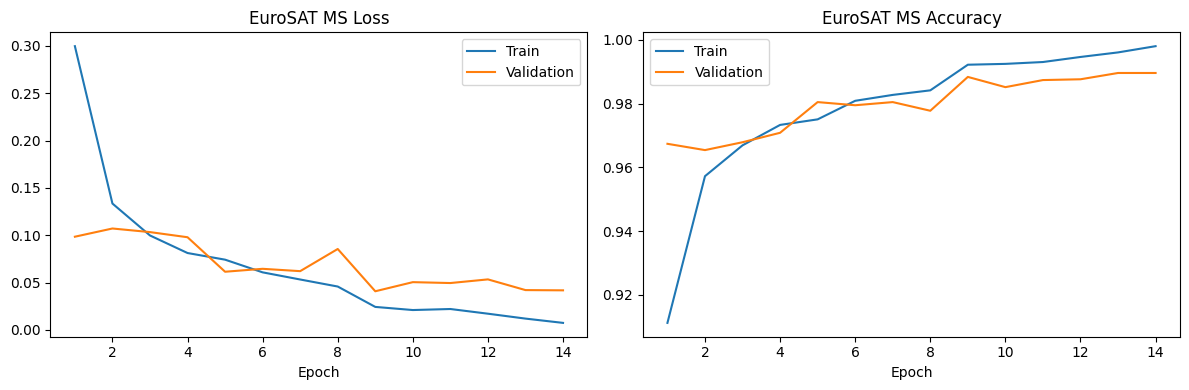

In [47]:
MS_EPOCHS = 20
MS_EARLY_STOP_PATIENCE = 5
MS_CHECKPOINT_PATH = Path("best_resnet50_eurosat_multispectral.pth")
MS_HISTORY = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}
MS_BEST_VAL_LOSS = float("inf")
MS_BEST_EPOCH = 0
MS_WAIT = 0
MS_BEST_STATE = None

seed_value = int(globals().get("SEED", 42))
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_value)
MS_TRAINING_START = time.perf_counter()

for epoch in range(1, MS_EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = run_ms_epoch(MS_MODEL, MS_TRAIN_LOADER, training=True)
    val_loss, val_accuracy = run_ms_epoch(MS_MODEL, MS_VAL_LOADER, training=False)
    MS_SCHEDULER.step(val_loss)

    MS_HISTORY["train_loss"].append(train_loss)
    MS_HISTORY["val_loss"].append(val_loss)
    MS_HISTORY["train_accuracy"].append(train_accuracy)
    MS_HISTORY["val_accuracy"].append(val_accuracy)

    if val_loss < MS_BEST_VAL_LOSS:
        MS_BEST_VAL_LOSS = val_loss
        MS_BEST_EPOCH = epoch
        MS_WAIT = 0
        MS_BEST_STATE = {
            key: value.detach().cpu().clone()
            for key, value in MS_MODEL.state_dict().items()
        }
    else:
        MS_WAIT += 1

    current_lr = MS_OPTIMIZER.param_groups[0]["lr"]
    print(
        f"Epoch {epoch:02d}/{MS_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"lr {current_lr:.2e} | {time.perf_counter() - epoch_start:.1f}s"
    )
    if MS_WAIT >= MS_EARLY_STOP_PATIENCE:
        print(f"Early stopping: validation loss did not improve for {MS_EARLY_STOP_PATIENCE} epochs.")
        break

MS_TRAINING_SECONDS = time.perf_counter() - MS_TRAINING_START
if MS_BEST_STATE is None:
    raise RuntimeError("Training did not produce a validation-selected checkpoint.")

MS_MODEL.load_state_dict(MS_BEST_STATE)
torch.save({
    "model_state_dict": MS_BEST_STATE,
    "class_names": MS_CLASS_NAMES,
    "class_to_idx": MS_CLASS_TO_IDX,
    "band_order": EUROSAT_MS_BAND_ORDER,
    "normalization_mean": MS_BAND_MEAN.tolist(),
    "normalization_std": MS_BAND_STD.tolist(),
    "image_size": MS_IMAGE_SIZE,
    "split_mode": MS_SPLIT_MODE,
    "train_indices": MS_TRAIN_INDICES.tolist(),
    "validation_indices": MS_VAL_INDICES.tolist(),
    "test_indices": MS_TEST_INDICES.tolist(),
    "best_epoch": MS_BEST_EPOCH,
    "best_validation_loss": MS_BEST_VAL_LOSS,
    "training_seconds": MS_TRAINING_SECONDS,
}, MS_CHECKPOINT_PATH)

print(
    f"Best epoch: {MS_BEST_EPOCH} | best validation loss: {MS_BEST_VAL_LOSS:.4f}"
)
print(f"Training time: {MS_TRAINING_SECONDS:.1f}s")
print(f"Saved checkpoint: {MS_CHECKPOINT_PATH.resolve()}")
print(f"Checkpoint size: {MS_CHECKPOINT_PATH.stat().st_size / (1024 ** 2):.2f} MiB")

ms_epochs = range(1, len(MS_HISTORY["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ms_epochs, MS_HISTORY["train_loss"], label="Train")
axes[0].plot(ms_epochs, MS_HISTORY["val_loss"], label="Validation")
axes[0].set(title="EuroSAT MS Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(ms_epochs, MS_HISTORY["train_accuracy"], label="Train")
axes[1].plot(ms_epochs, MS_HISTORY["val_accuracy"], label="Validation")
axes[1].set(title="EuroSAT MS Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


## 51. One-Time Held-Out Test Evaluation

After training and checkpoint selection are complete, this cell restores the best validation checkpoint and runs the held-out test set once. The test results are for final reporting only.

Expected output: accuracy plus macro precision, recall, and F1; details follow in the report and confusion-matrix stage.


In [48]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

if not MS_CHECKPOINT_PATH.exists():
    raise FileNotFoundError("Run the manual multispectral training cell before test evaluation.")

ms_checkpoint = torch.load(MS_CHECKPOINT_PATH, map_location="cpu", weights_only=True)
if ms_checkpoint["class_names"] != MS_CLASS_NAMES:
    raise ValueError("Checkpoint class mapping differs from the active multispectral dataset.")
if ms_checkpoint["band_order"] != EUROSAT_MS_BAND_ORDER:
    raise ValueError("Checkpoint band order differs from the active multispectral dataset.")

MS_MODEL.load_state_dict(ms_checkpoint["model_state_dict"])
MS_MODEL = MS_MODEL.to(MS_DEVICE).eval()
MS_TEST_LABELS = []
MS_TEST_PREDICTIONS = []

with torch.no_grad():
    for images, labels in MS_TEST_LOADER:
        logits = MS_MODEL(images.to(MS_DEVICE, non_blocking=True))
        predictions = logits.argmax(dim=1).cpu().numpy()
        MS_TEST_PREDICTIONS.extend(predictions.tolist())
        MS_TEST_LABELS.extend(labels.numpy().tolist())

MS_TEST_LABELS = np.asarray(MS_TEST_LABELS, dtype=np.int64)
MS_TEST_PREDICTIONS = np.asarray(MS_TEST_PREDICTIONS, dtype=np.int64)
ms_macro_precision, ms_macro_recall, ms_macro_f1, _ = precision_recall_fscore_support(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    average="macro",
    zero_division=0,
)
MS_TEST_METRICS = {
    "accuracy": float(accuracy_score(MS_TEST_LABELS, MS_TEST_PREDICTIONS)),
    "macro_precision": float(ms_macro_precision),
    "macro_recall": float(ms_macro_recall),
    "macro_f1": float(ms_macro_f1),
    "test_images": int(len(MS_TEST_LABELS)),
}
print(f"Multispectral held-out test accuracy: {MS_TEST_METRICS['accuracy']:.4f}")
print(f"Macro precision: {MS_TEST_METRICS['macro_precision']:.4f}")
print(f"Macro recall:    {MS_TEST_METRICS['macro_recall']:.4f}")
print(f"Macro F1-score:  {MS_TEST_METRICS['macro_f1']:.4f}")
print("Test images:", MS_TEST_METRICS["test_images"])


Multispectral held-out test accuracy: 0.9854
Macro precision: 0.9850
Macro recall:    0.9848
Macro F1-score:  0.9849
Test images: 4050


## 52. Classification Report and Confusion Matrix

The table reports per-class precision, recall, F1, and support. The confusion matrix uses true classes as rows and predicted classes as columns.

Expected output: per-class test performance and a 10×10 confusion matrix.


                      precision    recall  f1-score   support

          AnnualCrop     0.9822    0.9822    0.9822       450
              Forest     1.0000    0.9889    0.9944       450
HerbaceousVegetation     0.9610    0.9867    0.9737       450
             Highway     0.9840    0.9813    0.9826       375
          Industrial     0.9920    0.9947    0.9933       375
             Pasture     0.9733    0.9733    0.9733       300
       PermanentCrop     0.9784    0.9653    0.9718       375
         Residential     0.9978    0.9933    0.9955       450
               River     0.9815    0.9893    0.9854       375
             SeaLake     1.0000    0.9933    0.9967       450

            accuracy                         0.9854      4050
           macro avg     0.9850    0.9848    0.9849      4050
        weighted avg     0.9855    0.9854    0.9855      4050



,precision,recall,f1-score,support
AnnualCrop,0.9822,0.9822,0.9822,450.0
Forest,1.0000,0.9889,0.9944,450.0
HerbaceousVegetation,0.9610,0.9867,0.9737,450.0
Highway,0.9840,0.9813,0.9826,375.0
Industrial,0.9920,0.9947,0.9933,375.0
Pasture,0.9733,0.9733,0.9733,300.0
PermanentCrop,0.9784,0.9653,0.9718,375.0
Residential,0.9978,0.9933,0.9955,450.0
River,0.9815,0.9893,0.9854,375.0
SeaLake,1.0000,0.9933,0.9967,450.0


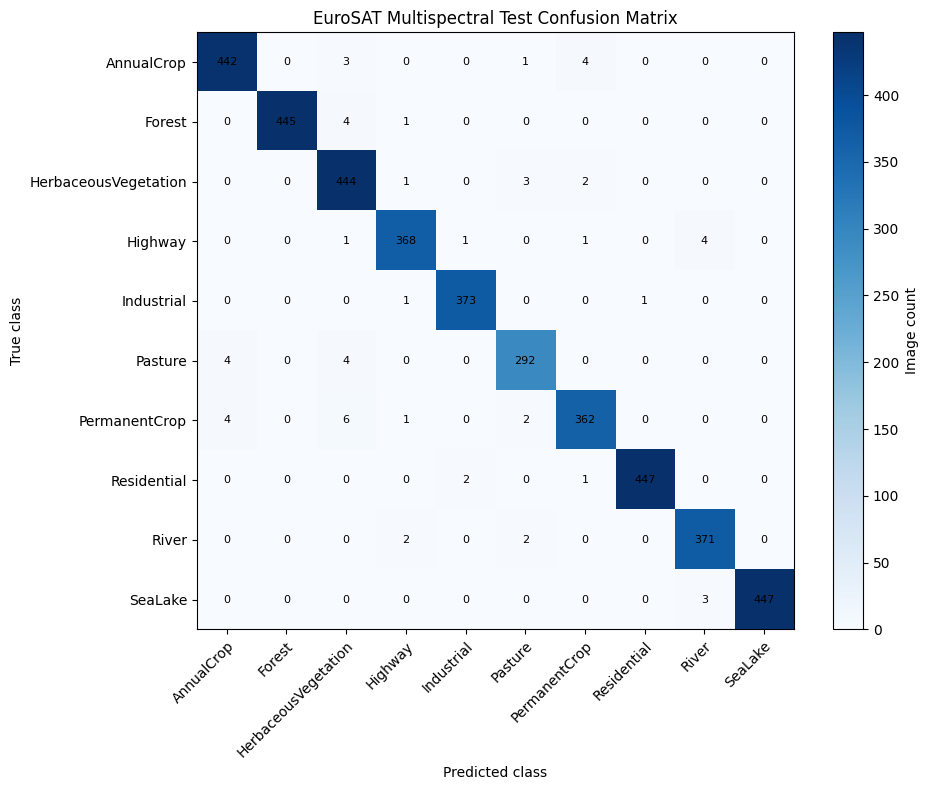

In [49]:
from sklearn.metrics import classification_report, confusion_matrix

MS_CLASSIFICATION_REPORT = classification_report(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    target_names=MS_CLASS_NAMES,
    output_dict=True,
    digits=4,
    zero_division=0,
)
print(classification_report(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
    target_names=MS_CLASS_NAMES,
    digits=4,
    zero_division=0,
))

MS_PER_CLASS_REPORT = pd.DataFrame(
    MS_CLASSIFICATION_REPORT
).T.loc[MS_CLASS_NAMES, ["precision", "recall", "f1-score", "support"]]
display(MS_PER_CLASS_REPORT.round(4))

MS_CONFUSION = confusion_matrix(
    MS_TEST_LABELS,
    MS_TEST_PREDICTIONS,
    labels=np.arange(MS_NUM_CLASSES),
)
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(MS_CONFUSION, cmap="Blues")
ax.set(
    xticks=np.arange(MS_NUM_CLASSES),
    yticks=np.arange(MS_NUM_CLASSES),
    xticklabels=MS_CLASS_NAMES,
    yticklabels=MS_CLASS_NAMES,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Multispectral Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(MS_NUM_CLASSES):
    for column in range(MS_NUM_CLASSES):
        ax.text(column, row, str(MS_CONFUSION[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()


## 53. RGB vs. Multispectral Comparison

This comparison combines the already recorded RGB test results with the actual multispectral evaluation after you run the new training/evaluation cells. Training time and saved-checkpoint size are read from the run/checkpoint when available. ResNet50 RGB time is estimated by summing its displayed one-decimal epoch durations (about 102.3 seconds); EfficientNet-B0 time is taken from its training timer.

If filename/class keys matched, all three models share the same underlying RGB test samples and split. Otherwise the MS result comes from its own reproducible stratified split, so test metrics should be read as separate evaluations. RGB uses three visible channels; the MS model uses all 13 Sentinel-2 bands and training-only band statistics. The MS metrics remain blank until the new model is actually trained and evaluated.

Expected output: accuracy, macro precision/recall/F1, training time, checkpoint size, test sample count, and a comparison chart.


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Training time (s),Checkpoint size (MiB),Test images
0,ResNet50 RGB,0.9820,0.9811,0.9817,0.9814,102.3000,90.0526,4050
1,EfficientNet-B0 RGB,0.9605,0.9588,0.9604,0.9592,144.4135,15.6094,4050
2,ResNet50 Multispectral (13 bands),0.9854,0.9850,0.9848,0.9849,524.6780,90.2545,4050


MS split mode: same RGB samples and same RGB split (filename/class keys matched)
ResNet50 RGB logged-time estimate: 102.3s (rounded epoch logs).


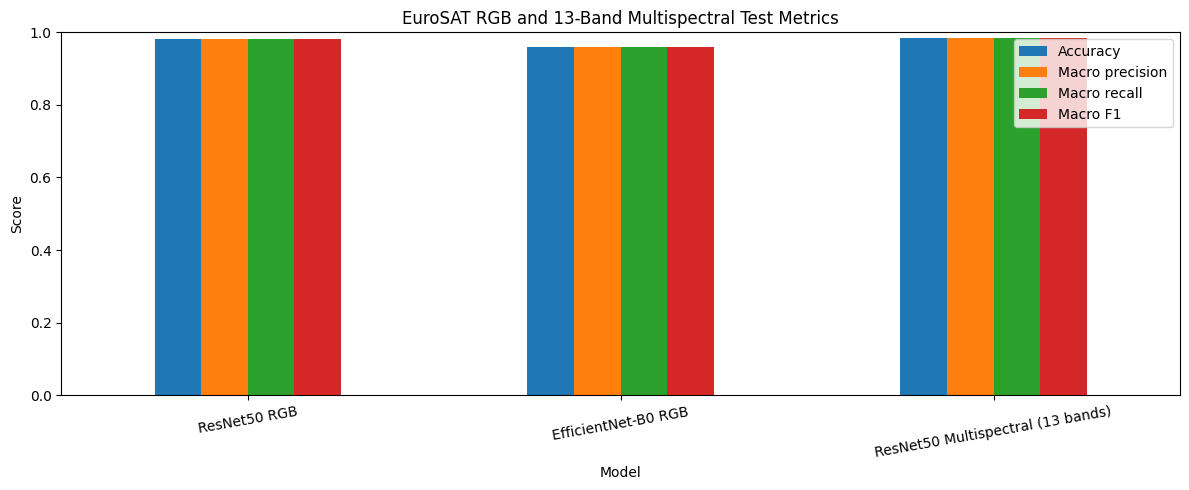

In [50]:
from sklearn.metrics import accuracy_score, classification_report

def checkpoint_size_mib(path):
    path = Path(path)
    return path.stat().st_size / (1024 ** 2) if path.exists() else np.nan

comparison_rows = []
resnet_rgb_time_approx = np.nan
if "all_labels" in globals() and "all_predictions" in globals():
    resnet_report = classification_report(
        all_labels, all_predictions, labels=np.arange(len(class_names)),
        target_names=class_names, output_dict=True, zero_division=0
    )
    resnet_epoch_seconds_from_saved_log = [
        11.4, 9.7, 10.3, 9.8, 10.0, 10.3, 10.4, 10.4, 9.8, 10.2,
    ]
    resnet_rgb_time_approx = sum(resnet_epoch_seconds_from_saved_log)
    resnet_path = Path(globals().get("MODEL_PATH", "best_resnet50_eurosat.pth"))
    comparison_rows.append({
        "Model": "ResNet50 RGB",
        "Accuracy": accuracy_score(all_labels, all_predictions),
        "Macro precision": resnet_report["macro avg"]["precision"],
        "Macro recall": resnet_report["macro avg"]["recall"],
        "Macro F1": resnet_report["macro avg"]["f1-score"],
        "Training time (s)": resnet_rgb_time_approx,
        "Checkpoint size (MiB)": checkpoint_size_mib(resnet_path),
        "Test images": len(all_labels),
    })

if "efficientnet_test_labels" in globals() and "efficientnet_test_predictions" in globals():
    efficientnet_report_for_ms_comparison = classification_report(
        efficientnet_test_labels,
        efficientnet_test_predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    efficientnet_path = Path(
        globals().get("EFFICIENTNET_MODEL_PATH", "best_efficientnet_b0_eurosat.pth")
    )
    comparison_rows.append({
        "Model": "EfficientNet-B0 RGB",
        "Accuracy": accuracy_score(efficientnet_test_labels, efficientnet_test_predictions),
        "Macro precision": efficientnet_report_for_ms_comparison["macro avg"]["precision"],
        "Macro recall": efficientnet_report_for_ms_comparison["macro avg"]["recall"],
        "Macro F1": efficientnet_report_for_ms_comparison["macro avg"]["f1-score"],
        "Training time (s)": globals().get("efficientnet_training_seconds", np.nan),
        "Checkpoint size (MiB)": checkpoint_size_mib(efficientnet_path),
        "Test images": len(efficientnet_test_labels),
    })

if "MS_TEST_METRICS" in globals():
    comparison_rows.append({
        "Model": "ResNet50 Multispectral (13 bands)",
        "Accuracy": MS_TEST_METRICS["accuracy"],
        "Macro precision": MS_TEST_METRICS["macro_precision"],
        "Macro recall": MS_TEST_METRICS["macro_recall"],
        "Macro F1": MS_TEST_METRICS["macro_f1"],
        "Training time (s)": globals().get("MS_TRAINING_SECONDS", np.nan),
        "Checkpoint size (MiB)": checkpoint_size_mib(
            globals().get("MS_CHECKPOINT_PATH", "best_resnet50_eurosat_multispectral.pth")
        ),
        "Test images": MS_TEST_METRICS["test_images"],
    })
else:
    comparison_rows.append({
        "Model": "ResNet50 Multispectral (13 bands)",
        "Accuracy": np.nan,
        "Macro precision": np.nan,
        "Macro recall": np.nan,
        "Macro F1": np.nan,
        "Training time (s)": np.nan,
        "Checkpoint size (MiB)": checkpoint_size_mib(
            "best_resnet50_eurosat_multispectral.pth"
        ),
        "Test images": len(MS_TEST_INDICES) if "MS_TEST_INDICES" in globals() else np.nan,
    })

MS_RGB_COMPARISON = pd.DataFrame(comparison_rows)
display(MS_RGB_COMPARISON.round(4))
print("MS split mode:", globals().get("MS_SPLIT_MODE", "not prepared"))
if np.isfinite(resnet_rgb_time_approx):
    print(f"ResNet50 RGB logged-time estimate: {resnet_rgb_time_approx:.1f}s (rounded epoch logs).")
if "MS_TEST_METRICS" not in globals():
    print("MS metrics are intentionally unreported until manual training and held-out evaluation.")

metric_columns = ["Accuracy", "Macro precision", "Macro recall", "Macro F1"]
ax = MS_RGB_COMPARISON.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 5), ylim=(0.0, 1.0)
)
ax.set_title("EuroSAT RGB and 13-Band Multispectral Test Metrics")
ax.set_ylabel("Score")
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()


## 54. Multispectral Pipeline Notes

- The RGB pipeline's original cells, outputs, and sample predictions are preserved above.
- The official multispectral ZIP is a separate source from the RGB dataset. Rasterio confirms TIFF band count and metadata; the code does not substitute RGB JPEGs.
- RGB uses 3 visible bands; multispectral input has 13 Sentinel-2 bands. The multispectral input is z-scored per band using training pixels only.
- The exact RGB split is reused only if every (class, filename stem) matches and labels agree; otherwise the MS split is reproducible and stratified.
- Training is deliberately manual. Test metrics and the final comparison are generated only after the new training and evaluation cells are run.


## 55. Joint Error Analysis: ResNet50 RGB and Multispectral

This stage performs final analysis on the existing held-out test split only. It does not train, fine-tune, or update model weights. It loads the saved ResNet50 RGB and 13-band checkpoints when available, and otherwise uses the already-loaded, evaluated models. If a model, checkpoint, or test loader is unavailable, that model is skipped with a clear message.

We compare class-wise precision, recall, and F1, inspect both confusion matrices, rank the largest true-to-predicted confusions, and display representative mistakes with their true and predicted labels. For multispectral images, the displayed picture is a B04/B03/B02 true-color preview; the classifier itself receives all 13 bands.


In [51]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from torchvision import models

ANALYSIS_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ANALYSIS_CLASS_NAMES = list(
    globals().get("class_names", globals().get("MS_CLASS_NAMES", []))
)
if not ANALYSIS_CLASS_NAMES:
    raise RuntimeError("Class names are unavailable. Run the notebook's data setup cells first.")
ANALYSIS_NUM_CLASSES = len(ANALYSIS_CLASS_NAMES)

ANALYSIS_MODELS = {}
ANALYSIS_MODEL_NOTES = {}

def _build_resnet_from_checkpoint(checkpoint_path, expected_channels):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    state_dict = checkpoint.get("model_state_dict", checkpoint)
    checkpoint_classes = checkpoint.get("class_names", ANALYSIS_CLASS_NAMES)
    if list(checkpoint_classes) != ANALYSIS_CLASS_NAMES:
        raise ValueError("Checkpoint class order does not match the notebook class order.")
    if "conv1.weight" not in state_dict:
        raise KeyError("Checkpoint is missing the ResNet stem weights.")
    if int(state_dict["conv1.weight"].shape[1]) != expected_channels:
        raise ValueError(
            f"Checkpoint expects {state_dict['conv1.weight'].shape[1]} input channels; "
            f"expected {expected_channels}."
        )

    resnet = models.resnet50(weights=None)
    if expected_channels != 3:
        old_stem = resnet.conv1
        resnet.conv1 = nn.Conv2d(
            expected_channels,
            old_stem.out_channels,
            kernel_size=old_stem.kernel_size,
            stride=old_stem.stride,
            padding=old_stem.padding,
            bias=False,
        )
    resnet.fc = nn.Linear(resnet.fc.in_features, ANALYSIS_NUM_CLASSES)
    resnet.load_state_dict(state_dict)
    return resnet

def _load_analysis_model(kind, expected_channels):
    if kind == "rgb":
        path = Path(globals().get("MODEL_PATH", "best_resnet50_eurosat.pth"))
        object_names = ("loaded_model", "model")
        best_state_name = "best_model_state"
    else:
        path = Path(
            globals().get(
                "MS_CHECKPOINT_PATH",
                "best_resnet50_eurosat_multispectral.pth",
            )
        )
        object_names = ("MS_MODEL",)
        best_state_name = "MS_BEST_STATE"

    checkpoint_error = None
    if path.exists():
        try:
            model_instance = _build_resnet_from_checkpoint(path, expected_channels)
            ANALYSIS_MODEL_NOTES[kind] = f"Loaded checkpoint: {path}"
            return model_instance.to(ANALYSIS_DEVICE).eval()
        except Exception as error:
            checkpoint_error = f"Could not load {path}: {type(error).__name__}: {error}"

    # If the file is unavailable, reuse an evaluated model already held in memory.
    for object_name in object_names:
        source_model = globals().get(object_name)
        if not isinstance(source_model, nn.Module):
            continue
        if int(source_model.conv1.in_channels) != expected_channels:
            continue

        best_state = globals().get(best_state_name)
        is_known_trained = (
            kind == "rgb"
            and (object_name == "loaded_model" or best_state is not None)
        ) or (
            kind == "multispectral"
            and (
                best_state is not None
                or "MS_TEST_PREDICTIONS" in globals()
                or "MS_TEST_METRICS" in globals()
            )
        )
        if not is_known_trained:
            continue

        model_instance = copy.deepcopy(source_model)
        if best_state is not None:
            model_instance.load_state_dict(best_state)
        ANALYSIS_MODEL_NOTES[kind] = (
            f"Reused already-loaded model: {object_name}"
            + (f"; checkpoint note: {checkpoint_error}" if checkpoint_error else "")
        )
        return model_instance.to(ANALYSIS_DEVICE).eval()

    if checkpoint_error:
        ANALYSIS_MODEL_NOTES[kind] = checkpoint_error
    else:
        ANALYSIS_MODEL_NOTES[kind] = (
            f"No checkpoint or evaluated in-memory model found for {kind}."
        )
    return None

ANALYSIS_MODELS["ResNet50 RGB"] = _load_analysis_model("rgb", expected_channels=3)
ANALYSIS_MODELS["ResNet50 Multispectral"] = _load_analysis_model(
    "multispectral", expected_channels=13
)

for model_name, model_instance in ANALYSIS_MODELS.items():
    if model_instance is None:
        print(f"{model_name}: skipped. {ANALYSIS_MODEL_NOTES['rgb' if model_name.endswith('RGB') else 'multispectral']}")
    else:
        expected_channels = 3 if model_name.endswith("RGB") else 13
        assert model_instance.conv1.in_channels == expected_channels
        assert model_instance.fc.out_features == ANALYSIS_NUM_CLASSES
        print(
            f"{model_name}: ready | input channels={model_instance.conv1.in_channels} | "
            f"classes={model_instance.fc.out_features} | device={ANALYSIS_DEVICE}"
        )
        print("  " + ANALYSIS_MODEL_NOTES["rgb" if model_name.endswith("RGB") else "multispectral"])

def _predict_test_loader(model_instance, loader, expected_channels):
    true_labels = []
    predicted_labels = []
    probabilities = []
    model_instance.eval()
    with torch.inference_mode():
        for images, labels in loader:
            if images.ndim != 4 or images.shape[1] != expected_channels:
                raise ValueError(
                    f"Expected input shape (batch, {expected_channels}, height, width); "
                    f"received {tuple(images.shape)}."
                )
            logits = model_instance(images.to(ANALYSIS_DEVICE, non_blocking=True))
            batch_probabilities = torch.softmax(logits, dim=1).cpu().numpy()
            probabilities.extend(batch_probabilities)
            predicted_labels.extend(batch_probabilities.argmax(axis=1).tolist())
            true_labels.extend(labels.cpu().numpy().tolist())
    return (
        np.asarray(true_labels, dtype=np.int64),
        np.asarray(predicted_labels, dtype=np.int64),
        np.asarray(probabilities, dtype=np.float32),
    )

ANALYSIS_SPECS = {
    "ResNet50 RGB": {
        "model_key": "ResNet50 RGB",
        "loader_name": "test_loader",
        "channels": 3,
        "cached_true": "all_labels",
        "cached_pred": "all_predictions",
    },
    "ResNet50 Multispectral": {
        "model_key": "ResNet50 Multispectral",
        "loader_name": "MS_TEST_LOADER",
        "channels": 13,
        "cached_true": "MS_TEST_LABELS",
        "cached_pred": "MS_TEST_PREDICTIONS",
    },
}

ERROR_ANALYSIS_RESULTS = {}
for model_name, spec in ANALYSIS_SPECS.items():
    model_instance = ANALYSIS_MODELS[spec["model_key"]]
    loader = globals().get(spec["loader_name"])
    if model_instance is not None and loader is not None:
        try:
            y_true, y_pred, y_prob = _predict_test_loader(
                model_instance, loader, spec["channels"]
            )
            ERROR_ANALYSIS_RESULTS[model_name] = {
                "y_true": y_true,
                "y_pred": y_pred,
                "probabilities": y_prob,
            }
            print(
                f"{model_name}: analyzed {len(y_true):,} held-out test images "
                f"using {spec['channels']} input channels."
            )
            continue
        except Exception as error:
            print(
                f"{model_name}: test-loader inference unavailable "
                f"({type(error).__name__}: {error})."
            )

    cached_true = globals().get(spec["cached_true"])
    cached_pred = globals().get(spec["cached_pred"])
    if cached_true is not None and cached_pred is not None:
        y_true = np.asarray(cached_true, dtype=np.int64)
        y_pred = np.asarray(cached_pred, dtype=np.int64)
        if len(y_true) == len(y_pred):
            ERROR_ANALYSIS_RESULTS[model_name] = {
                "y_true": y_true,
                "y_pred": y_pred,
                "probabilities": None,
            }
            print(f"{model_name}: using its existing cached test predictions.")
            continue

    reason = ANALYSIS_MODEL_NOTES[
        "rgb" if model_name.endswith("RGB") else "multispectral"
    ]
    print(
        f"{model_name}: skipped because its test data/predictions are unavailable. "
        f"{reason} Upload or restore the saved checkpoint and run the existing "
        "test-data preparation/evaluation cells; no training is required."
    )

if not ERROR_ANALYSIS_RESULTS:
    print(
        "No error analysis was run. Restore the existing model checkpoints and "
        "test loaders, then rerun these analysis cells."
    )


ResNet50 RGB: ready | input channels=3 | classes=10 | device=cuda
  Loaded checkpoint: best_resnet50_eurosat.pth
ResNet50 Multispectral: ready | input channels=13 | classes=10 | device=cuda
  Loaded checkpoint: best_resnet50_eurosat_multispectral.pth
ResNet50 RGB: analyzed 4,050 held-out test images using 3 input channels.
ResNet50 Multispectral: analyzed 4,050 held-out test images using 13 input channels.


Held-out test error summary:


,Model,Test images,Incorrect,Accuracy,Macro precision,Macro recall,Macro F1
0,ResNet50 RGB,4050,73,0.9820,0.9811,0.9817,0.9814
1,ResNet50 Multispectral,4050,59,0.9854,0.9850,0.9848,0.9849


Per-class Precision, Recall, and F1:


,Class,ResNet50 RGB precision,ResNet50 RGB recall,ResNet50 RGB F1,ResNet50 Multispectral precision,ResNet50 Multispectral recall,ResNet50 Multispectral F1,F1 delta (MS - RGB)
0,AnnualCrop,0.9797,0.9644,0.9720,0.9822,0.9822,0.9822,0.0102
1,Forest,0.9933,0.9956,0.9945,1.0000,0.9889,0.9944,-0.0000
2,HerbaceousVegetation,0.9647,0.9711,0.9679,0.9610,0.9867,0.9737,0.0058
3,Highway,0.9789,0.9920,0.9854,0.9840,0.9813,0.9826,-0.0028
4,Industrial,0.9947,0.9947,0.9947,0.9920,0.9947,0.9933,-0.0013
5,Pasture,0.9577,0.9800,0.9687,0.9733,0.9733,0.9733,0.0046
6,PermanentCrop,0.9649,0.9520,0.9584,0.9784,0.9653,0.9718,0.0134
7,Residential,0.9956,0.9978,0.9967,0.9978,0.9933,0.9955,-0.0011
8,River,0.9839,0.9787,0.9813,0.9815,0.9893,0.9854,0.0041
9,SeaLake,0.9978,0.9911,0.9944,1.0000,0.9933,0.9967,0.0022


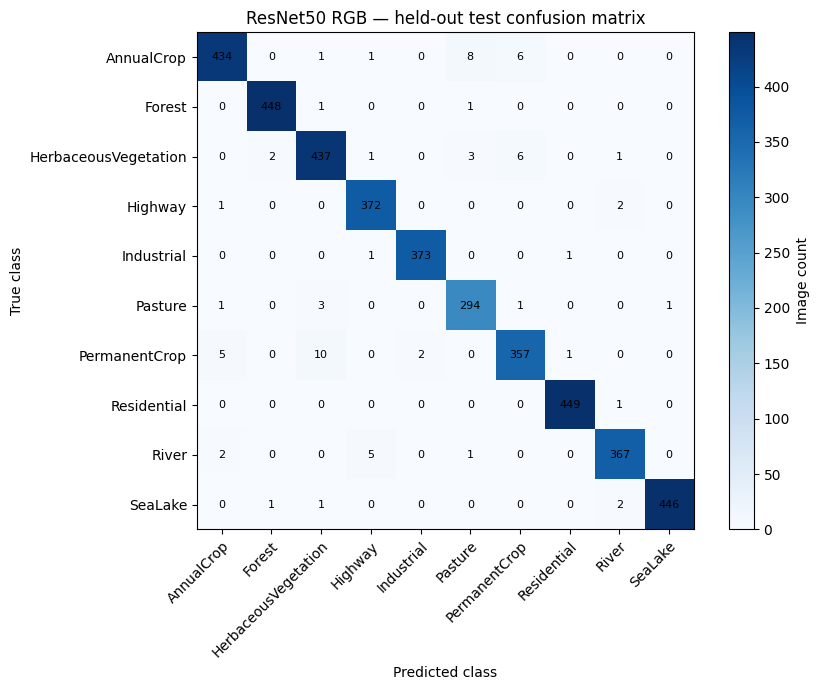

ResNet50 RGB: largest directed confusion pairs


,True class,Predicted class,Count
0,PermanentCrop,HerbaceousVegetation,10
1,AnnualCrop,Pasture,8
2,HerbaceousVegetation,PermanentCrop,6
3,AnnualCrop,PermanentCrop,6
4,PermanentCrop,AnnualCrop,5
5,River,Highway,5
6,Pasture,HerbaceousVegetation,3
7,HerbaceousVegetation,Pasture,3


Most involved class in off-diagonal errors: PermanentCrop (31 error counts across its row/column).
Lowest class-wise F1: PermanentCrop.


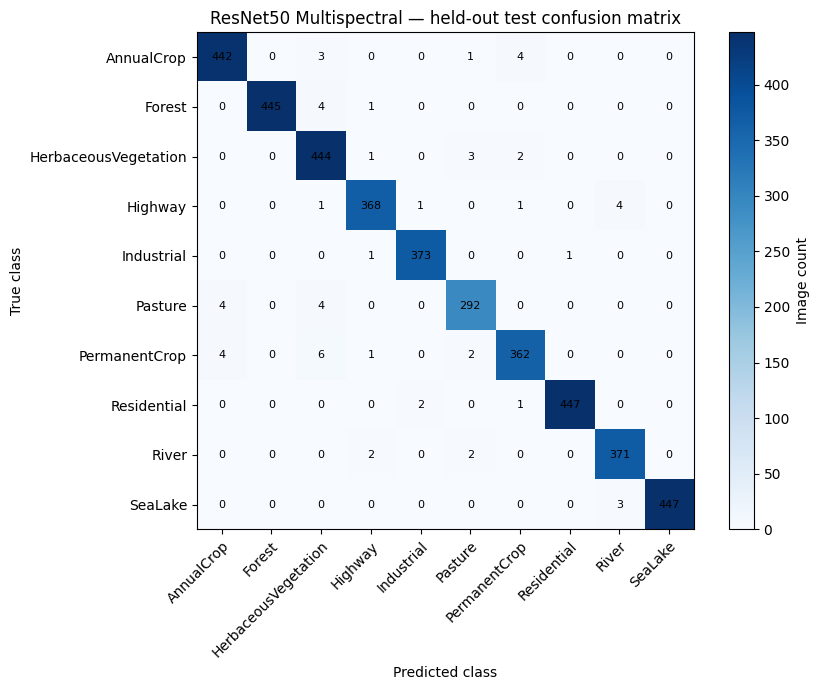

ResNet50 Multispectral: largest directed confusion pairs


,True class,Predicted class,Count
0,PermanentCrop,HerbaceousVegetation,6
1,Forest,HerbaceousVegetation,4
2,Pasture,HerbaceousVegetation,4
3,Highway,River,4
4,Pasture,AnnualCrop,4
5,PermanentCrop,AnnualCrop,4
6,AnnualCrop,PermanentCrop,4
7,HerbaceousVegetation,Pasture,3


Most involved class in off-diagonal errors: HerbaceousVegetation (24 error counts across its row/column).
Lowest class-wise F1: PermanentCrop.


In [52]:
ERROR_ANALYSIS_SUMMARY_ROWS = []
ERROR_ANALYSIS_REPORTS = {}
ERROR_ANALYSIS_CONFUSIONS = {}

for model_name, result in ERROR_ANALYSIS_RESULTS.items():
    y_true = result["y_true"]
    y_pred = result["y_pred"]
    report_dict = classification_report(
        y_true,
        y_pred,
        labels=np.arange(ANALYSIS_NUM_CLASSES),
        target_names=ANALYSIS_CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(ANALYSIS_NUM_CLASSES),
    )
    ERROR_ANALYSIS_REPORTS[model_name] = report_dict
    ERROR_ANALYSIS_CONFUSIONS[model_name] = matrix
    ERROR_ANALYSIS_SUMMARY_ROWS.append({
        "Model": model_name,
        "Test images": len(y_true),
        "Incorrect": int(np.count_nonzero(y_true != y_pred)),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": report_dict["macro avg"]["precision"],
        "Macro recall": report_dict["macro avg"]["recall"],
        "Macro F1": report_dict["macro avg"]["f1-score"],
    })

print("Held-out test error summary:")
display(pd.DataFrame(ERROR_ANALYSIS_SUMMARY_ROWS).round(4))

classwise_comparison = pd.DataFrame({"Class": ANALYSIS_CLASS_NAMES})
for model_name, report_dict in ERROR_ANALYSIS_REPORTS.items():
    classwise_comparison[f"{model_name} precision"] = [
        report_dict[name]["precision"] for name in ANALYSIS_CLASS_NAMES
    ]
    classwise_comparison[f"{model_name} recall"] = [
        report_dict[name]["recall"] for name in ANALYSIS_CLASS_NAMES
    ]
    classwise_comparison[f"{model_name} F1"] = [
        report_dict[name]["f1-score"] for name in ANALYSIS_CLASS_NAMES
    ]

if {"ResNet50 RGB F1", "ResNet50 Multispectral F1"}.issubset(classwise_comparison.columns):
    classwise_comparison["F1 delta (MS - RGB)"] = (
        classwise_comparison["ResNet50 Multispectral F1"]
        - classwise_comparison["ResNet50 RGB F1"]
    )
print("Per-class Precision, Recall, and F1:")
display(classwise_comparison.round(4))

def _rank_confusion_pairs(matrix, class_names, limit=8):
    pairs = []
    for true_index in range(len(class_names)):
        for predicted_index in range(len(class_names)):
            if true_index == predicted_index:
                continue
            count = int(matrix[true_index, predicted_index])
            if count:
                pairs.append({
                    "True class": class_names[true_index],
                    "Predicted class": class_names[predicted_index],
                    "Count": count,
                })
    return pd.DataFrame(pairs).sort_values(
        "Count", ascending=False
    ).head(limit).reset_index(drop=True) if pairs else pd.DataFrame(
        columns=["True class", "Predicted class", "Count"]
    )

for model_name, matrix in ERROR_ANALYSIS_CONFUSIONS.items():
    fig, ax = plt.subplots(figsize=(9, 7))
    image_plot = ax.imshow(matrix, cmap="Blues")
    ax.set(
        xticks=np.arange(ANALYSIS_NUM_CLASSES),
        yticks=np.arange(ANALYSIS_NUM_CLASSES),
        xticklabels=ANALYSIS_CLASS_NAMES,
        yticklabels=ANALYSIS_CLASS_NAMES,
        xlabel="Predicted class",
        ylabel="True class",
        title=f"{model_name} — held-out test confusion matrix",
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for row in range(ANALYSIS_NUM_CLASSES):
        for column in range(ANALYSIS_NUM_CLASSES):
            ax.text(column, row, str(matrix[row, column]),
                    ha="center", va="center", fontsize=8)
    fig.colorbar(image_plot, ax=ax, label="Image count")
    plt.tight_layout()
    plt.show()

    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pair_table = _rank_confusion_pairs(matrix, ANALYSIS_CLASS_NAMES)
    class_involvement = off_diagonal.sum(axis=0) + off_diagonal.sum(axis=1)
    most_involved_index = int(class_involvement.argmax())
    worst_f1_class = min(
        ANALYSIS_CLASS_NAMES,
        key=lambda name: classwise_comparison.loc[
            classwise_comparison["Class"] == name,
            f"{model_name} F1",
        ].iloc[0],
    ) if f"{model_name} F1" in classwise_comparison.columns else "unavailable"

    print(f"{model_name}: largest directed confusion pairs")
    display(pair_table)
    print(
        f"Most involved class in off-diagonal errors: "
        f"{ANALYSIS_CLASS_NAMES[most_involved_index]} "
        f"({int(class_involvement[most_involved_index])} error counts across its row/column)."
    )
    print(f"Lowest class-wise F1: {worst_f1_class}.")


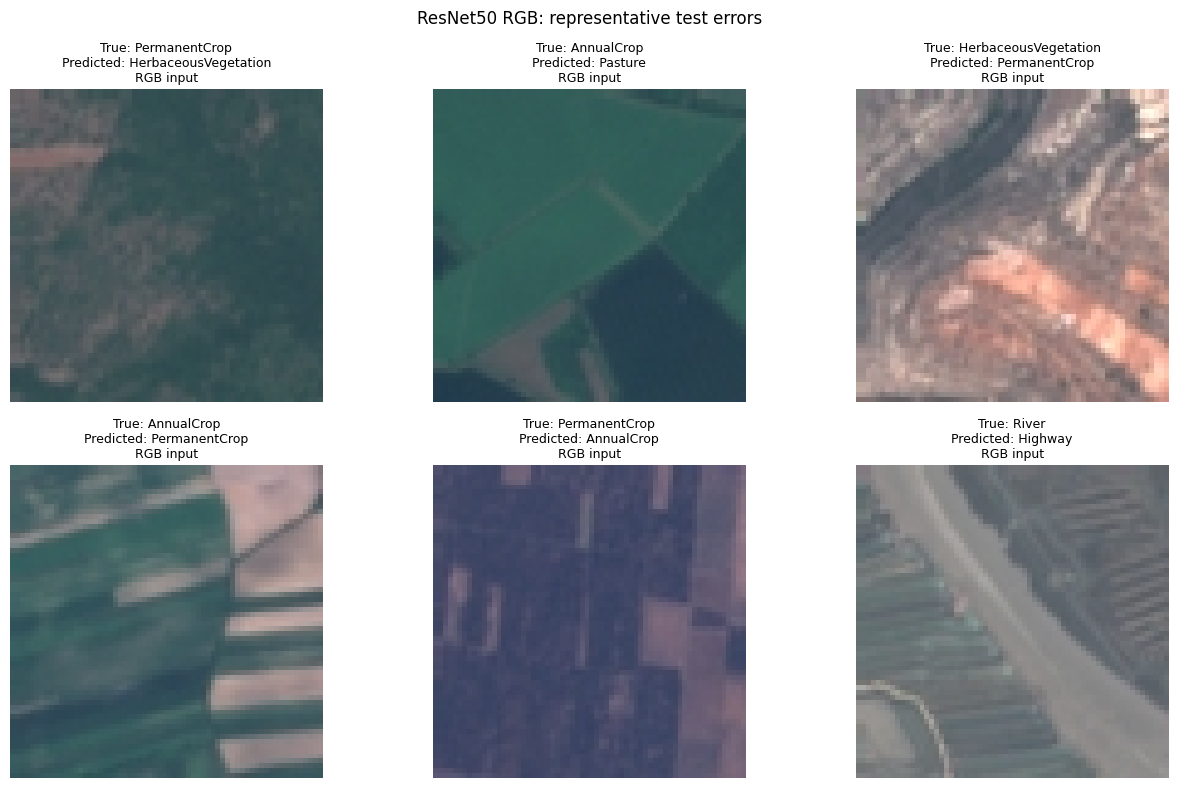

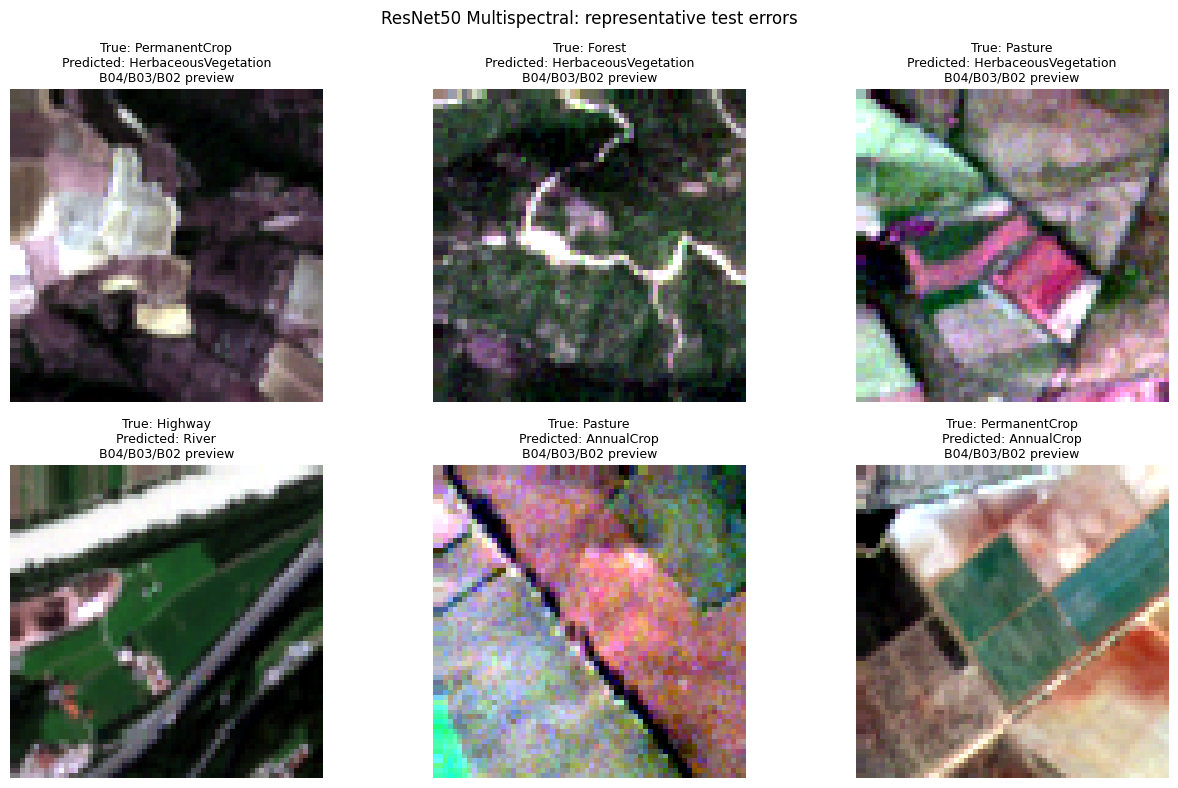

In [53]:
def _rgb_test_preview(test_position):
    if "test_set" in globals() and "dataset" in globals():
        source_index = int(test_set.indices[int(test_position)])
        image, _ = dataset[source_index]
        return np.asarray(image.convert("RGB") if hasattr(image, "convert") else image)
    if "test_set" in globals():
        tensor, _ = test_set[int(test_position)]
        image = tensor.detach().cpu().float().numpy()
        mean = np.asarray(globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))[:, None, None]
        std = np.asarray(globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))[:, None, None]
        return np.clip(((image * std + mean).transpose(1, 2, 0)), 0, 1)
    raise RuntimeError("RGB test images are unavailable.")

def _multispectral_true_color_preview(record_index):
    if "MS_RECORDS" not in globals() or "read_eurosat_ms" not in globals():
        raise RuntimeError("Multispectral TIFF records or Rasterio loader are unavailable.")
    data, nodata_values, masks = read_eurosat_ms(
        MS_RECORDS[int(record_index)]["path"]
    )
    valid_pixels = valid_ms_pixels(data, nodata_values, masks)
    # Canonical channel order: B04, B03, B02 is the RGB display composite.
    selected = data[[3, 2, 1]].astype(np.float32)
    selected_valid = np.all(valid_pixels[[3, 2, 1]], axis=0)
    preview = np.zeros((*selected.shape[1:], 3), dtype=np.float32)
    for display_channel in range(3):
        channel = selected[display_channel]
        values = channel[selected_valid & np.isfinite(channel)]
        if values.size:
            low, high = np.percentile(values, [2, 98])
            if high > low:
                preview[..., display_channel] = np.clip(
                    (channel - low) / (high - low), 0, 1
                )
    return preview

def _representative_error_positions(result, maximum=6):
    y_true = result["y_true"]
    y_pred = result["y_pred"]
    wrong_positions = np.flatnonzero(y_true != y_pred)
    if wrong_positions.size == 0:
        return []

    matrix = confusion_matrix(
        y_true, y_pred, labels=np.arange(ANALYSIS_NUM_CLASSES)
    )
    pair_table = _rank_confusion_pairs(
        matrix, ANALYSIS_CLASS_NAMES, limit=maximum
    )
    selected = []
    for _, pair in pair_table.iterrows():
        true_index = ANALYSIS_CLASS_NAMES.index(pair["True class"])
        pred_index = ANALYSIS_CLASS_NAMES.index(pair["Predicted class"])
        candidates = np.flatnonzero((y_true == true_index) & (y_pred == pred_index))
        if candidates.size:
            selected.append(int(candidates[0]))
        if len(selected) >= maximum:
            break
    for position in wrong_positions:
        if int(position) not in selected:
            selected.append(int(position))
        if len(selected) >= maximum:
            break
    return selected

for model_name, result in ERROR_ANALYSIS_RESULTS.items():
    error_positions = _representative_error_positions(result, maximum=6)
    if not error_positions:
        print(f"{model_name}: no misclassified images on this test split.")
        continue

    is_multispectral = model_name.endswith("Multispectral")
    try:
        fig, axes = plt.subplots(2, 3, figsize=(13, 8))
        axes = axes.ravel()
        for axis, position in zip(axes, error_positions):
            true_index = int(result["y_true"][position])
            pred_index = int(result["y_pred"][position])
            if is_multispectral:
                record_index = int(MS_TEST_SET.indices[position])
                image = _multispectral_true_color_preview(record_index)
                source_note = "B04/B03/B02 preview"
            else:
                image = _rgb_test_preview(position)
                source_note = "RGB input"

            axis.imshow(image)
            axis.set_title(
                f"True: {ANALYSIS_CLASS_NAMES[true_index]}\n"
                f"Predicted: {ANALYSIS_CLASS_NAMES[pred_index]}\n"
                f"{source_note}",
                fontsize=9,
            )
            axis.axis("off")
        for axis in axes[len(error_positions):]:
            axis.axis("off")
        fig.suptitle(f"{model_name}: representative test errors")
        plt.tight_layout()
        plt.show()
    except Exception as error:
        print(
            f"{model_name}: prediction analysis is available, but image display "
            f"was skipped ({type(error).__name__}: {error})."
        )


## 56. Grad-CAM for RGB and 13-Band ResNet50

Grad-CAM highlights spatial regions whose last-block activations support the model's predicted class. For a correct example the target is the correct prediction; for a mistake the target is the model's incorrect predicted class. Warm colors indicate stronger positive contribution to that chosen score, not a causal explanation.

For each model this stage selects one correct and one incorrect held-out test image when both are available. It shows the input preview, heatmap, and overlay. The multispectral heatmap is computed from all 13 channels; the displayed B04/B03/B02 composite is only a human-readable visual reference.

Expected output: side-by-side Grad-CAM visualizations for correctly and incorrectly classified test images. No training or parameter updates occur.


In [54]:
import torch.nn.functional as F

def generate_analysis_gradcam(model_instance, image_tensor, expected_channels, target_class=None):
    if image_tensor.ndim == 3:
        image_tensor = image_tensor.unsqueeze(0)
    if image_tensor.ndim != 4 or image_tensor.shape[1] != expected_channels:
        raise ValueError(
            f"Grad-CAM expected (batch, {expected_channels}, H, W), "
            f"received {tuple(image_tensor.shape)}."
        )

    model_instance.eval()
    image_tensor = image_tensor.to(ANALYSIS_DEVICE)
    activations = {}
    gradients = {}
    target_layer = model_instance.layer4[-1]

    def _capture_activation(module, inputs, output):
        activations["value"] = output
        output.register_hook(lambda gradient: gradients.__setitem__("value", gradient))

    hook_handle = target_layer.register_forward_hook(_capture_activation)
    model_instance.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits = model_instance(image_tensor)
            predicted_index = int(logits.argmax(dim=1)[0].item())
            cam_target = predicted_index if target_class is None else int(target_class)
            logits[0, cam_target].backward()

        if "value" not in activations or "value" not in gradients:
            raise RuntimeError("Grad-CAM did not capture the target-layer activations/gradients.")

        activation = activations["value"].detach()
        gradient = gradients["value"].detach()
        channel_weights = gradient.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((channel_weights * activation).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=tuple(image_tensor.shape[-2:]),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        cam -= cam.min()
        maximum = cam.max()
        if float(maximum.item()) > 0:
            cam /= maximum
        probabilities = torch.softmax(logits.detach(), dim=1)[0]
        return (
            cam.cpu().numpy(),
            predicted_index,
            float(probabilities[predicted_index].item()),
            cam_target,
        )
    finally:
        hook_handle.remove()
        model_instance.zero_grad(set_to_none=True)

print("Grad-CAM helper ready. Target layer: ResNet50 layer4[-1].")


Grad-CAM helper ready. Target layer: ResNet50 layer4[-1].


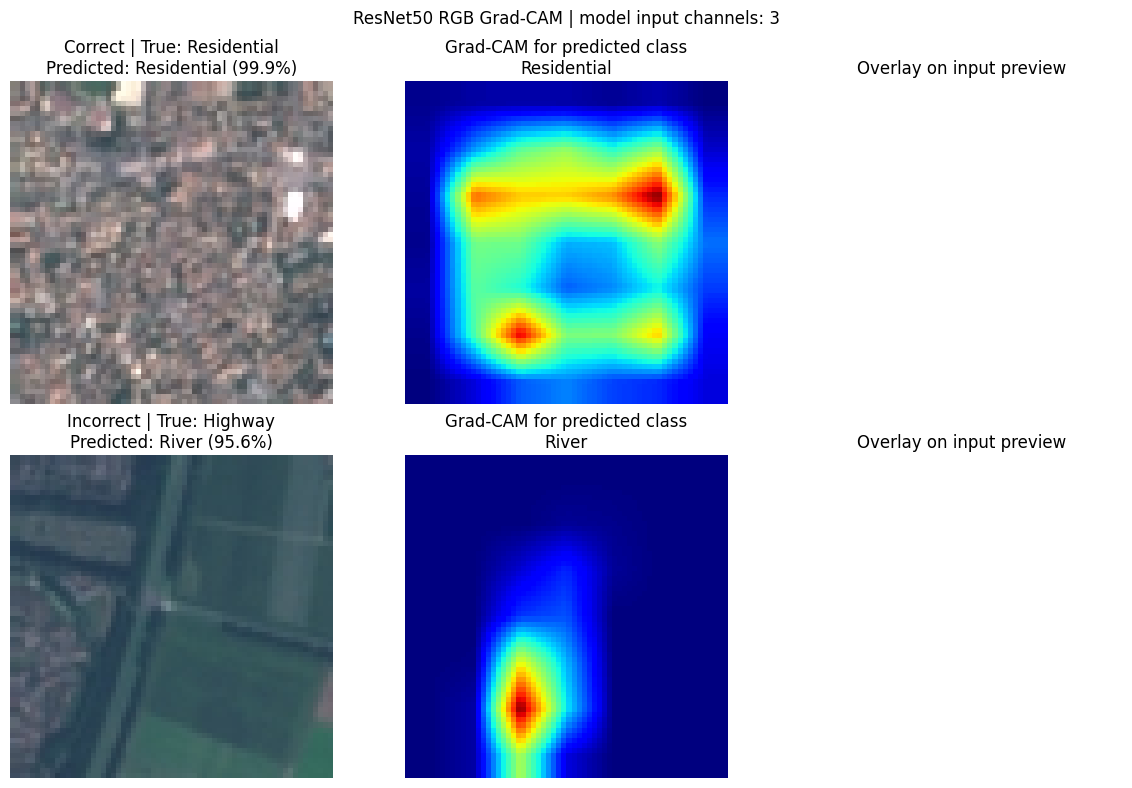

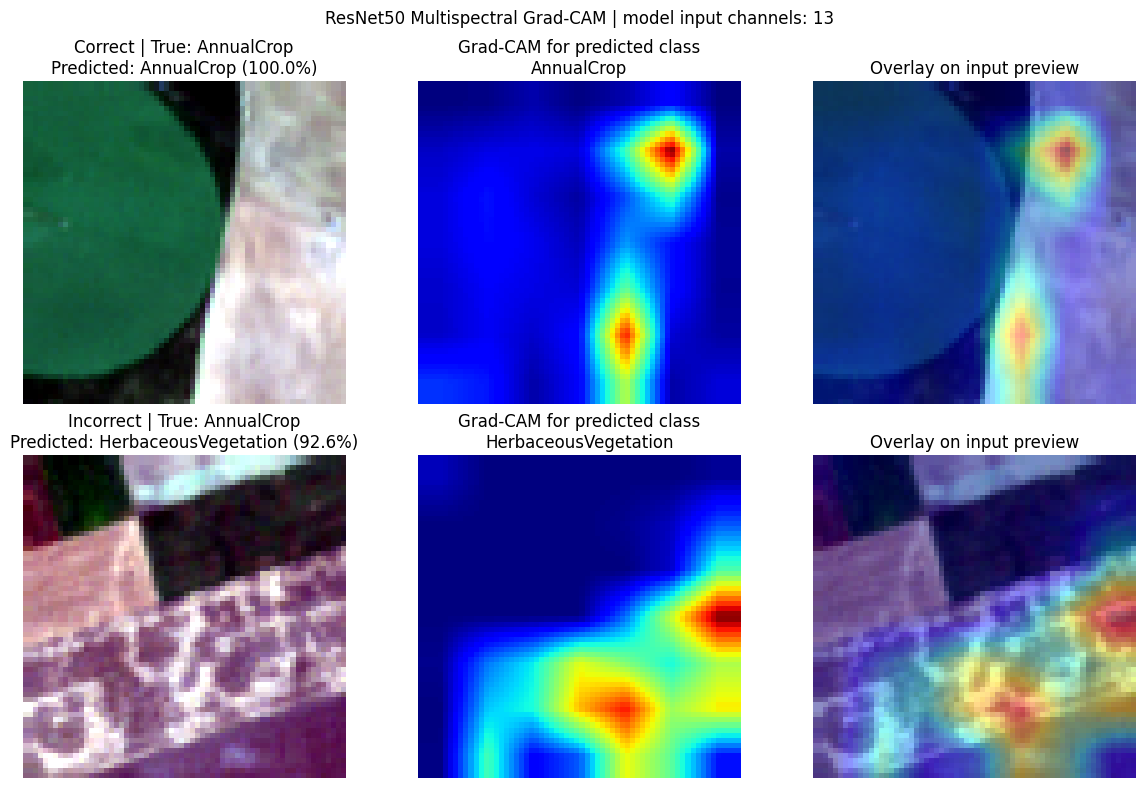

In [55]:
def _analysis_tensor_at_position(model_name, position):
    if model_name == "ResNet50 RGB":
        if "test_set" not in globals():
            raise RuntimeError("RGB test_set is unavailable.")
        return test_set[int(position)][0]
    if "MS_TEST_SET" not in globals():
        raise RuntimeError("MS_TEST_SET is unavailable.")
    return MS_TEST_SET[int(position)][0]

def _analysis_preview_at_position(model_name, position):
    if model_name == "ResNet50 RGB":
        return _rgb_test_preview(position)
    record_index = int(MS_TEST_SET.indices[int(position)])
    return _multispectral_true_color_preview(record_index)

for model_name, model_instance in ANALYSIS_MODELS.items():
    result = ERROR_ANALYSIS_RESULTS.get(model_name)
    if model_instance is None or result is None:
        print(f"{model_name}: Grad-CAM skipped because model or test predictions are unavailable.")
        continue

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    correct_positions = np.flatnonzero(y_true == y_pred)
    incorrect_positions = np.flatnonzero(y_true != y_pred)
    selected_examples = []
    if correct_positions.size:
        selected_examples.append(("Correct", int(correct_positions[0])))
    if incorrect_positions.size:
        selected_examples.append(("Incorrect", int(incorrect_positions[0])))
    if not selected_examples:
        print(f"{model_name}: test set is empty; no Grad-CAM examples to display.")
        continue

    expected_channels = 3 if model_name.endswith("RGB") else 13
    fig, axes = plt.subplots(
        len(selected_examples), 3,
        figsize=(12, 4 * len(selected_examples)),
        squeeze=False,
    )
    for row_index, (status, position) in enumerate(selected_examples):
        try:
            input_tensor = _analysis_tensor_at_position(model_name, position)
            if input_tensor.shape[0] != expected_channels:
                raise ValueError(
                    f"{model_name} test item has {input_tensor.shape[0]} channels; "
                    f"expected {expected_channels}."
                )
            preview = _analysis_preview_at_position(model_name, position)
            cam, predicted_index, confidence, cam_target = generate_analysis_gradcam(
                model_instance,
                input_tensor,
                expected_channels=expected_channels,
            )
            cam_tensor = torch.from_numpy(cam).float()[None, None]
            cam_for_preview = F.interpolate(
                cam_tensor,
                size=preview.shape[:2],
                mode="bilinear",
                align_corners=False,
            )[0, 0].numpy()
            colored_cam = plt.get_cmap("jet")(cam_for_preview)[..., :3]
            overlay = np.clip(0.55 * preview + 0.45 * colored_cam, 0, 1)

            true_index = int(y_true[position])
            axes[row_index, 0].imshow(preview)
            axes[row_index, 0].set_title(
                f"{status} | True: {ANALYSIS_CLASS_NAMES[true_index]}\n"
                f"Predicted: {ANALYSIS_CLASS_NAMES[predicted_index]} ({confidence:.1%})"
            )
            axes[row_index, 1].imshow(cam_for_preview, cmap="jet", vmin=0, vmax=1)
            axes[row_index, 1].set_title(
                f"Grad-CAM for predicted class\n{ANALYSIS_CLASS_NAMES[cam_target]}"
            )
            axes[row_index, 2].imshow(overlay)
            axes[row_index, 2].set_title("Overlay on input preview")
            for axis in axes[row_index]:
                axis.axis("off")
        except Exception as error:
            for axis in axes[row_index]:
                axis.axis("off")
            axes[row_index, 0].text(
                0.02, 0.5,
                f"{status} example unavailable:\n{type(error).__name__}: {error}",
                transform=axes[row_index, 0].transAxes,
                wrap=True,
            )

    fig.suptitle(
        f"{model_name} Grad-CAM | model input channels: {expected_channels}"
    )
    plt.tight_layout()
    plt.show()


## 38. Optional Gradio App Preparation

This separate cell prepares an upload interface with an image preview, predicted class/confidence, and top-three classes. Select the deployment model after reviewing validation results. The cell only launches the interface when you run it manually. [Gradio Image component documentation](https://www.gradio.app/docs/gradio/image).

In [56]:
try:
    import gradio as gr
except ImportError as error:
    raise ImportError("Install Gradio in Colab with pip install gradio, then rerun this cell.") from error

DEPLOY_MODEL_NAME = "ResNet50"  # Set to "EfficientNet-B0" after reviewing validation performance.
if DEPLOY_MODEL_NAME == "ResNet50":
    deployment_model = loaded_model
elif DEPLOY_MODEL_NAME == "EfficientNet-B0":
    deployment_model = efficientnet_model
else:
    raise ValueError("DEPLOY_MODEL_NAME must be 'ResNet50' or 'EfficientNet-B0'.")
deployment_model.eval()

def predict_for_gradio(pil_image):
    if pil_image is None:
        return None, "Upload an RGB satellite image.", {}
    pil_image = pil_image.convert("RGB")
    image_tensor = eval_transform(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(deployment_model(image_tensor), dim=1)[0]
    top_probabilities, top_indices = probabilities.topk(3)
    predicted_index = int(top_indices[0].item())
    prediction_text = (
        f"Prediction: {class_names[predicted_index]} "
        f"({top_probabilities[0].item():.1%} model score)"
    )
    top_three = {
        class_names[int(index.item())]: float(probability.item())
        for index, probability in zip(top_indices, top_probabilities)
    }
    return pil_image, prediction_text, top_three

with gr.Blocks(title="EuroSAT Land Cover Classifier") as demo:
    gr.Markdown("# EuroSAT Land Cover Classifier\nUpload an RGB satellite image to see the predicted class and top three scores.")
    with gr.Row():
        image_input = gr.Image(type="pil", label="Upload satellite image")
        image_preview = gr.Image(label="Image preview")
    prediction_output = gr.Textbox(label="Prediction")
    top_three_output = gr.Label(label="Top 3 classes", num_top_classes=3)
    predict_button = gr.Button("Classify image")
    predict_button.click(
        predict_for_gradio,
        inputs=image_input,
        outputs=[image_preview, prediction_output, top_three_output],
    )

# Run manually to start the local Colab interface; sharing is disabled by default.
demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 39. Final Project Documentation

### Problem and objectives
Land-cover classification assigns a satellite image to one of ten EuroSAT categories. This project builds a reproducible RGB baseline and compares it with a second transfer-learning architecture.

### Dataset and methodology
The RGB experiment uses EuroSAT's 27,000 64 × 64 images, a stratified 70/15/15 split, training-only augmentation, 224 × 224 inputs, and ImageNet normalization. The baseline uses pretrained ResNet50; the extension uses pretrained EfficientNet-B0. Each model selects weights using validation loss and reports final metrics on the held-out test set.

### Experimental results
The attached completed notebook reports **ResNet50 test accuracy = 98.20%**, macro precision = 98.11%, macro recall = 98.17%, and macro F1 = 98.14% across 4,050 test images. Its best validation epoch was 6. The recorded epoch durations sum to approximately 103.3 seconds (the displayed per-epoch values were rounded). EfficientNet-B0 results remain pending until its training/evaluation cells are run; the comparison table intentionally computes them from actual outputs.

### Explainability and multispectral scope
Grad-CAM highlights coarse regions associated with a class score; it helps inspect model behavior but does not prove causal reasoning. The current RGB weights accept three channels only. EuroSAT_MS is a separate 13-band dataset and needs its own aligned data pipeline, band-specific normalization, and a 13-channel first layer.

### Limitations and future work
The random image split is not a geographic holdout, so spatially related scenes could make generalization appear stronger than performance in a new region. Softmax scores are not calibrated probabilities. Metrics apply to this dataset and split; future work can compare models across geographic regions, test the multispectral dataset separately, calibrate confidence, and evaluate deployment latency on target hardware.

### References
- [EuroSAT paper](https://arxiv.org/abs/1709.00029)
- [EuroSAT RGB and multispectral files on Zenodo](https://zenodo.org/records/7711097)
- [Sentinel-2 MSI band-resolution specification](https://sentinels.copernicus.eu/documents/d/sentinel/sentinel-2-products-specification-document-15_1)
- [Torchvision EfficientNet-B0 documentation](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.efficientnet_b0.html)
- [Grad-CAM paper](https://arxiv.org/abs/1610.02391)
- [Gradio Image documentation](https://www.gradio.app/docs/gradio/image)


In [57]:
final_status = {
    "ResNet50 test accuracy": float(accuracy_score(all_labels, all_predictions)),
    "ResNet50 macro F1": float(baseline_report_dict["macro avg"]["f1-score"]),
    "EfficientNet trained": "efficientnet_test_accuracy" in globals(),
}
if final_status["EfficientNet trained"]:
    final_status["EfficientNet-B0 test accuracy"] = float(efficientnet_test_accuracy)
    final_status["EfficientNet-B0 macro F1"] = float(efficientnet_report_dict["macro avg"]["f1-score"])
else:
    final_status["EfficientNet-B0 test accuracy"] = "Run EfficientNet training and evaluation to populate."
display(pd.DataFrame([final_status]))

,ResNet50 test accuracy,ResNet50 macro F1,EfficientNet trained,EfficientNet-B0 test accuracy,EfficientNet-B0 macro F1
0,0.981975,0.98139,True,0.960494,0.959223


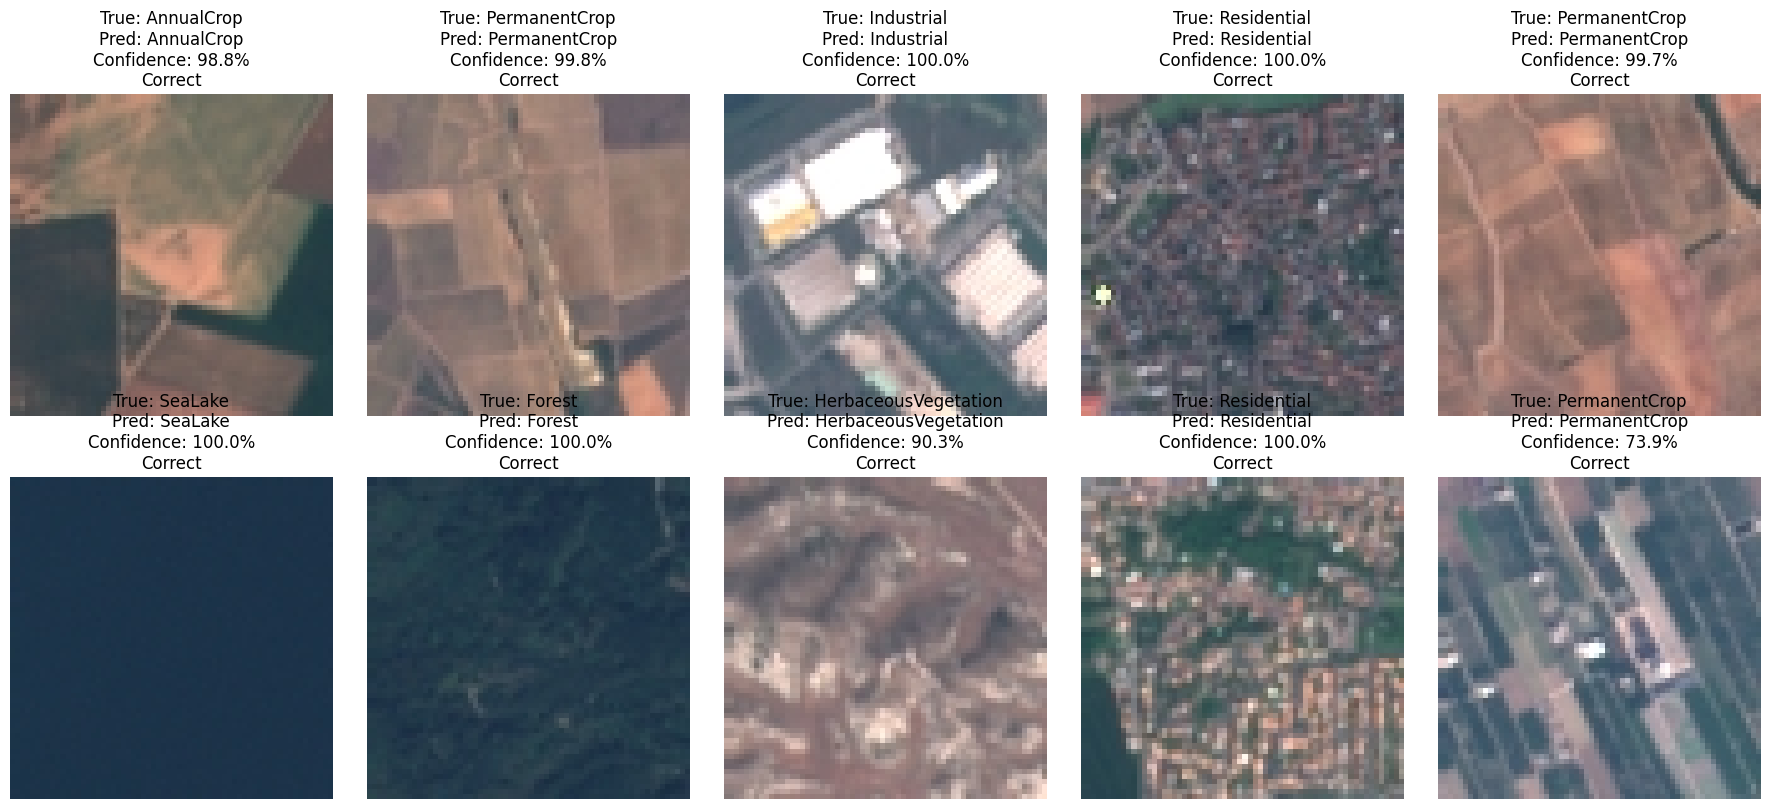

Correct Predictions: 10/10
Sample Accuracy: 100%


In [58]:
import random
import matplotlib.pyplot as plt
import torch

# Select 10 random images from the test dataset
random.seed(42)
sample_indices = random.sample(range(len(test_set)), 10)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

correct = 0

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    # Get original image
    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    # Predict
    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = loaded_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct Predictions: {correct}/10")
print(f"Sample Accuracy: {correct * 10}%")

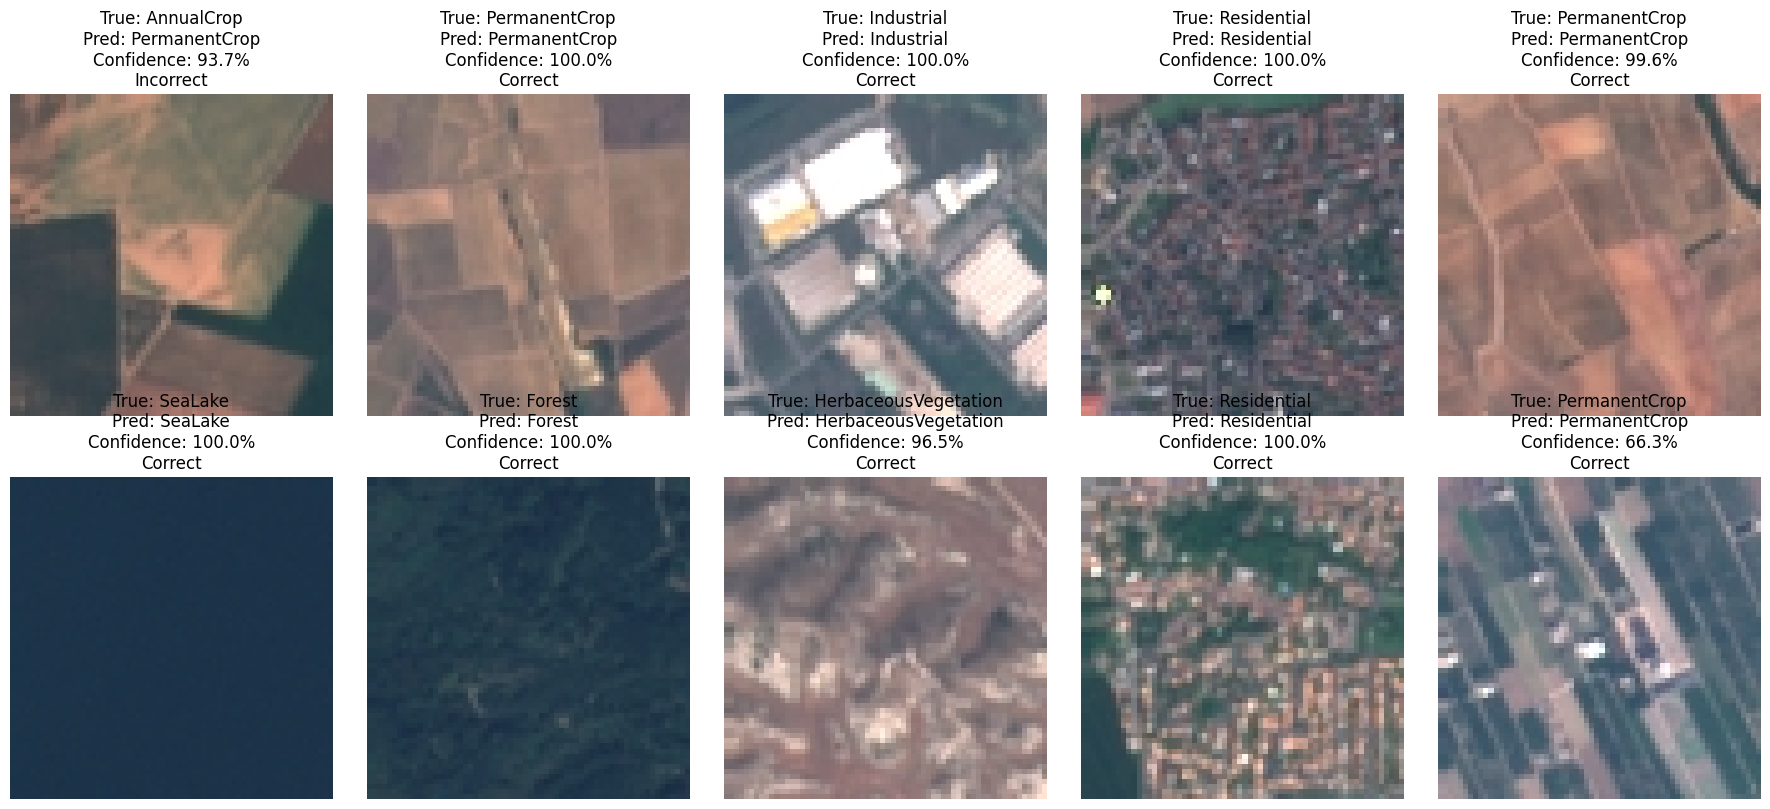

EfficientNet Correct: 9/10
EfficientNet Sample Accuracy: 90%


In [59]:
# Test EfficientNet-B0 on the same 10 images

efficientnet_model.eval()

correct = 0

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):

    image_tensor, true_label = test_set[idx]

    original_idx = test_set.indices[idx]
    original_image, _ = dataset[original_idx]

    image_batch = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = efficientnet_model(image_batch)
        probabilities = torch.softmax(outputs, dim=1)

    predicted_label = probabilities.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

    is_correct = predicted_label == true_label

    if is_correct:
        correct += 1

    ax.imshow(original_image)

    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1%}\n"
        f"{'Correct' if is_correct else 'Incorrect'}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"EfficientNet Correct: {correct}/10")
print(f"EfficientNet Sample Accuracy: {correct * 10}%")